# RESUMO

Com o advento da Indústria 4.0, torna-se mandatória a transição da Manutenção Baseada em Condição (CBM) com a monitoração de condições de operação e alarmes de alteração baseados em limites pré-estabelecidos para a Manutenção Preditiva para prover um diagnóstico cada vez mais precoce do estado de falha utilizando da Inteligência Artificial, em especial dos algoritmos de Aprendizado de Máquina (*Machine Learning*), cada vez mais disponíveis. Com este objetivo, este trabalho propõe uma metodologia para diagnosticar as condições de saúde e falha em máquinas rotativas, fundamentada na integração entre o processamento digital de sinais e o algoritmo *K-Nearest Neighbors* (KNN).

A abordagem utiliza a Resultante Euclidiana para a fusão de sinais vibratórios triaxiais, preservando em um único sinal os comportamentos físicos. Continua com a extração de atributos híbridos nos domínios do tempo e da frequência, submetidos ao refinamento estatístico via Amplitude Interquartílica (IQR) e ao escalonamento Z-Score. Na análise espectral das harmônicas via Transformada Rápida de Fourier (FFT) nota-se forte relevância das três primeiras harmônicas, provada na correlação de $r = 0,55$ da 3ª harmônica, consolidando-a como o principal descritor de severidade.

Como resultado, o classificador KNN atingiu uma acurácia de 98,44%, com destaque para a especificidade de 100%, eliminando a ocorrência de alarmes falsos, enquanto a sensibilidade atingiu 97,14%. O estudo demonstra que uma engenharia de atributos simples, aliada ao tratamento estatístico de dados, permite que modelos de baixa complexidade computacional ofereçam uma solução confiável e eficiente para diagnóstico preditivo em máquinas industriais.

**PALAVRAS-CHAVE:** Diagnóstico de falhas, Máquinas rotativas, Análise de vibração, Aprendizado de máquina, *K-Nearest Neighbors*.

# Importação das Bibliotecas

In [ ]:
# --- IMPORTAÇÃO DE BIBLIOTECAS ---

# Biblioteca para download automático de datasets do Kaggle
import kagglehub

# Manipulação de arquivos e caminhos do sistema operacional
import os

# Processamento numérico e manipulação de arrays (essencial para sinais)
import numpy as np

# Estruturação de dados em DataFrames (tabelas para a IA)
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from mpl_toolkits.mplot3d import Axes3D # Import for 3D plots

import seaborn as sns

# Leitura de arquivos binários do MATLAB (.mat)
from scipy.io import loadmat

# Ferramentas para Transformada de Fourier (Análise de Frequência)
from scipy.fft import fft, fftfreq

# Transformada de Hilbert (Útil para análise de envelope em vibrações)
from scipy.signal import hilbert

from scipy.stats import kurtosis

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder # Ferramentas para escalonamento e codificação de variáveis [cite: 27]
from sklearn.cluster import KMeans # Algoritmo de aprendizado não supervisionado para agrupamento [cite: 35]

from sklearn.decomposition import PCA # Técnica de redução de dimensionalidade para análise de componentes [cite: 35]

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.metrics import  classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score, silhouette_score
from sklearn.utils import resample

# IMPORTAÇÃO DOS CLASSIFICADORES
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC




# Download do dataset do Kaggle

In [ ]:
# --- DOWNLOAD DO DATASET ---

# O comando abaixo baixa a versão mais recente do dataset de Sumair Aziz.
# O caminho (path) retornado aponta para o local onde os arquivos .mat foram salvos.
path = kagglehub.dataset_download("sumairaziz/vibration-faults-dataset-for-rotating-machines")

print(f"Dataset baixado com sucesso em: {path}")

Using Colab cache for faster access to the 'vibration-faults-dataset-for-rotating-machines' dataset.
Dataset baixado com sucesso em: /kaggle/input/vibration-faults-dataset-for-rotating-machines


# Inspeção dos Dados Brutos (.mat)


In [ ]:
# 1. Definir caminhos para as pastas
healthy_dir = os.path.join(path, "Healthy")
faulty_dir = os.path.join(path, "Faulty")

# 2. Definir os nomes dos arquivos específicos a serem inspecionados
file_h_specific = "H26.mat"
file_f_specific = "F46.mat"

def inspecionar_mat_bruto(file_path, label):
    # Carrega o arquivo MATLAB
    raw_data = loadmat(file_path)

    # Filtra as chaves para encontrar a que contém os dados (ignora metadados __)
    data_key = [k for k in raw_data.keys() if not k.startswith('__')][0]

    # Extrai a matriz de dados
    matrix = raw_data[data_key]

    # Converte para DataFrame sem alterar valores
    df = pd.DataFrame(matrix)

    print(f"\n" + "="*50)
    print(f"--- INSPEÇÃO TÉCNICA ({label}) ---")
    print(f"Arquivo: {os.path.basename(file_path)}")
    print(f"Chave no .mat: '{data_key}'")
    print(f"Formato: {matrix.shape}")
    print("="*50)

    # Exibe as estatísticas básicas (Média, Desvio Padrão, Min, Max, Quartis)
    print(f"\nESTATÍSTICA DESCRITIVA ({label}):")
    print(df.describe())
    print("="*50)

    print(f"\nPRIMEIRAS LINHAS ({label}):")
    return df.head()

# Executar inspeção com os arquivos específicos
print(inspecionar_mat_bruto(os.path.join(healthy_dir, file_h_specific), "HEALTHY"))
print(inspecionar_mat_bruto(os.path.join(faulty_dir, file_f_specific), "FAULTY"))


--- INSPEÇÃO TÉCNICA (HEALTHY) ---
Arquivo: H26.mat
Chave no .mat: 'H'
Formato: (5000, 3)

ESTATÍSTICA DESCRITIVA (HEALTHY):
                 0            1            2
count  5000.000000  5000.000000  5000.000000
mean     -0.001283     0.001618    -0.000438
std       0.969062     1.006508     0.989703
min      -3.092217    -2.983284    -3.797709
25%      -0.659826    -0.703187    -0.578096
50%      -0.053669    -0.010739     0.125968
75%       0.622368     0.690968     0.737039
max       2.955439     3.839070     1.470978

PRIMEIRAS LINHAS (HEALTHY):
          0         1         2
0 -0.896128 -1.192358 -0.543226
1 -0.399899 -0.326784  0.288703
2 -1.283066 -0.853074  0.348468
3  1.838931 -1.030439  0.929648
4  0.354678 -0.184128 -1.919786

--- INSPEÇÃO TÉCNICA (FAULTY) ---
Arquivo: F46.mat
Chave no .mat: 'H'
Formato: (5000, 3)

ESTATÍSTICA DESCRITIVA (FAULTY):
                 0            1            2
count  5000.000000  5000.000000  5000.000000
mean     -0.002870     0.002165   

# 3.1 Sinal da Vibração Saudável e com Falha no tempo

A análise inicial dos sinais de vibração no domínio do tempo foi realizada a partir dos registros brutos dos 3 sinais triaxiais extraídos diretamente dos arquivos originais, funcionando como uma triagem qualitativa para observação do comportamento “Saudável” (Figura 1) e “Falha” (Figura 2).

Nesta fase, a observação não se prende a valores físicos absolutos ou escalas estatísticas, uma vez que os sinais brutos representam registros pontuais da amostra total e ainda não passaram por processos de normalização e estatísticos que levam em conta toda amostra. No entanto, a inspeção visual revela formas distintas para os sinais de “Saudável” e “Falha”.


In [ ]:
def plotar_vibracao_triaxial(file_path, label):
    # 1. Carregar dados
    raw_data = loadmat(file_path)
    data_key = [k for k in raw_data.keys() if not k.startswith('__')][0]
    matrix = raw_data[data_key]

    # Se estiver transposto, corrigimos para ter as colunas como eixos
    if matrix.shape[0] < matrix.shape[1]:
        matrix = matrix.T

    # 2. Criar vetor de tempo (assumindo fs=1000Hz)
    fs = 1000
    tempo = np.linspace(0, len(matrix)/fs, len(matrix))

    # 3. Plotagem
    plt.figure(figsize=(15, 5))
    plt.plot(tempo, matrix[:, 0], label='Eixo X', color='blue', alpha=0.7)
    plt.plot(tempo, matrix[:, 1], label='Eixo Y', color='green', alpha=0.7)
    plt.plot(tempo, matrix[:, 2], label='Eixo Z', color='red', alpha=0.7)

    plt.title(f"Sinal de Vibração no Tempo - Condição: {label} ({os.path.basename(file_path)})")
    plt.xlabel("Tempo (segundos)")
    plt.ylabel("Amplitude de Vibração")
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.ylim(-4, 4) # Ajustar a escala do eixo Y entre 0 e 5
    plt.show()

# Definir arquivos para visualização (usando H26 e F46 conforme solicitado)
healthy_sample = os.path.join(healthy_dir, "H26.mat")
faulty_sample = os.path.join(faulty_dir, "F46.mat")

# As chamadas para a função plotar_vibracao_triaxial serão movidas para células separadas abaixo.


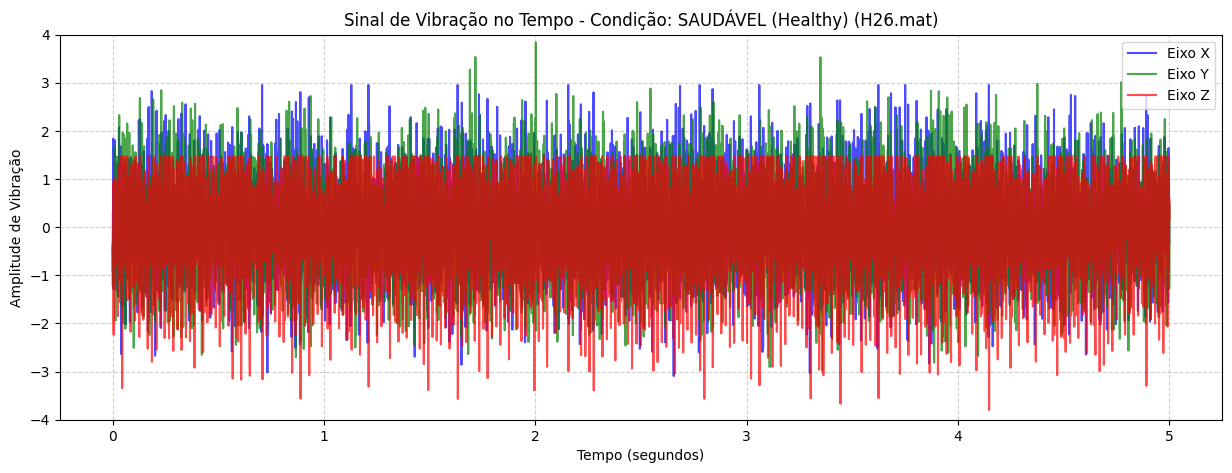

In [ ]:
plotar_vibracao_triaxial(healthy_sample, "SAUDÁVEL (Healthy)")

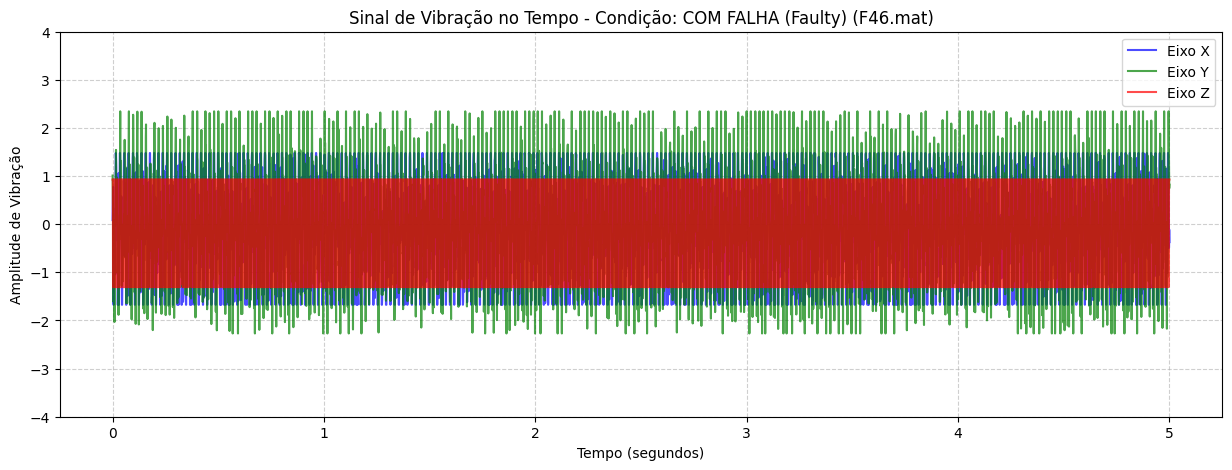

In [ ]:
plotar_vibracao_triaxial(faulty_sample, "COM FALHA (Faulty)")

# 3.2 Sinal da Vibração Saudável e com Falha depois da Resultante Euclidiana

A aplicação da Resultante Euclidiana consolida os 3 sinais axiais temporais de vibração em um vetor único de amplitude, permitindo uma análise centralizada da energia do sistema.

Assim, a Resultante Euclidiana atua como um indicador da condição operacional, sintetizando em um único sinal a trajetória temporal que torna possível a distinção entre o estado “Saudável” (Figura 3) e o com defeito (Figura 4) de maneira visual.

In [ ]:
def plotar_resultante_euclidiana(file_path, label, plot_color='purple'): # Define a função com parâmetros de caminho, rótulo e cor do gráfico
    # 1. Carregar e organizar dados do arquivo MAT
    raw_data = loadmat(file_path) # Carrega o arquivo .mat em um dicionário do Python
    data_key = [k for k in raw_data.keys() if not k.startswith('__')][0] # Identifica a primeira chave do dicionário que contém os dados úteis
    matrix = raw_data[data_key] # Extrai a matriz de dados correspondente à chave identificada

    # Garantir formato correto de matriz (Amostras nas linhas, Eixos nas colunas)
    if matrix.shape[0] < matrix.shape[1]: # Verifica se a matriz tem mais colunas do que linhas (formato incorreto)
        matrix = matrix.T # Transpõe a matriz para garantir que os eixos fiquem nas colunas

    x, y, z = matrix[:, 0], matrix[:, 1], matrix[:, 2] # Separa as três primeiras colunas como os eixos X, Y e Z

    # 2. Cálculo da Norma/Resultante Euclidiana (Magnitude Vetorial)
    magnitude = np.sqrt(x**2 + y**2 + z**2) # Calcula a raiz quadrada da soma dos quadrados dos três eixos

    # 3. Criar vetor de tempo em segundos (com base na frequência de amostragem fs=1000Hz)
    fs = 1000 # Define a frequência de amostragem como 1000 Hz (1000 amostras por segundo)
    tempo = np.linspace(0, len(magnitude)/fs, len(magnitude)) # Gera o vetor de tempo distribuído linearmente de 0 ao tempo total útil

    # 4. Configuração e exibição do gráfico do sinal no tempo
    plt.figure(figsize=(15, 5)) # Inicializa a figura do gráfico com dimensões de 15 por 5 polegadas
    plt.plot(tempo, magnitude, label='Resultante Euclidiana', color=plot_color, alpha=0.8) # Plota o tempo versus a magnitude com cor personalizada e transparência

    plt.title(f"Resultante Euclidiana no Tempo - Condição: {label} ({os.path.basename(file_path)})") # Define o título do gráfico dinamicamente com o rótulo e nome do arquivo
    plt.xlabel("Tempo (segundos)") # Configura o rótulo descritivo do eixo horizontal (X)
    plt.ylabel("Amplitude da Resultante Euclidiana") # Configura o rótulo descritivo do eixo vertical (Y)
    plt.legend(loc='upper right') # Adiciona a legenda explicativa no canto superior direito do gráfico
    plt.grid(True, linestyle='--', alpha=0.6) # Ativa as linhas de grade tracejadas com opacidade suave
    plt.ylim(0, 5) # Limita a visualização do eixo Y estritamente entre os valores 0 e 5
    plt.show() # Renderiza e exibe o gráfico finalizado na tela

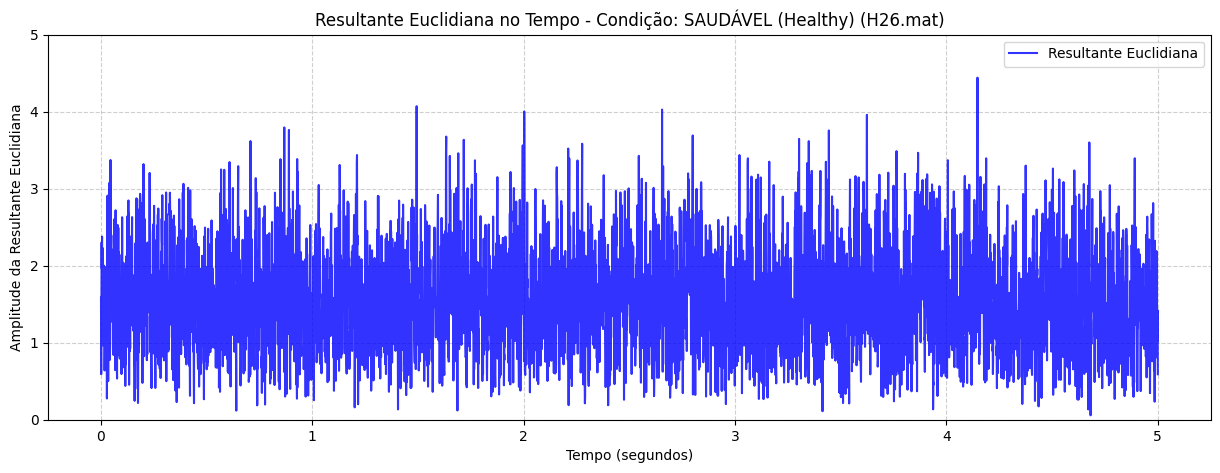

In [ ]:
plotar_resultante_euclidiana(healthy_sample, "SAUDÁVEL (Healthy)", plot_color='blue')

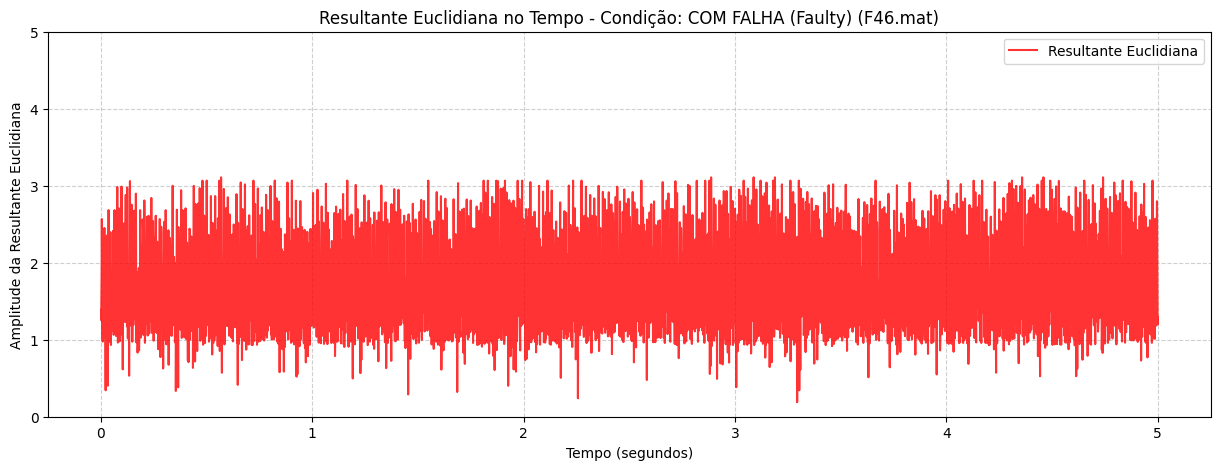

In [ ]:
plotar_resultante_euclidiana(faulty_sample, "COM FALHA (Faulty)", plot_color='red')

# 3.3.a Análise do Domínio da Frequência

## DADOS:
### Entrada: Arquivos Brutos temporais: 1 Saudável e 1 Falha
### Saída: Sinais de frequencia: 1 Saudável e 1 Falha

A conversão dos sinais para o domínio da frequência, via FFT (Figura 5), permitiu a validação da velocidade de rotação do motor e a identificação das assinaturas de funcionamento normal na 1ª harmônica e de defeito principalmente na 2ª e nas 3ª harmônicas.

A análise do espectro de frequência, executada com o sinal normalizado e escalonado, possibilitou a confirmação da rotação nominal do motor na detecção no primeiro pico de energia na frequência fundamental de 49,8 Hz (Tabela 1) com amplitude de $0,2221\sigma$, validando a adoção da velocidade de referência em 2980 RPM, já considerando o escorregamento.

Esta confirmação de velocidade de rotação é essencial para garantir que as análises futuras estejam embasadas na operação real do motor, permitindo a correta localização dos múltiplos de frequência fundamental (1X, 2X, 3X) que caracterizam fenômenos de desalinhamento e desbalanceamento.


      EXTRAÇÃO DE VALORES: ANÁLISE ESPECTRAL (HARMÔNICAS)
CONDIÇÃO: Saudável (Healthy) (H26.mat)
-> Harmônica 1X: Pico Real em  49.8 Hz | Amplitude: 0.2221 σ
-> Harmônica 2X: Pico Real em  99.4 Hz | Amplitude: 0.0676 σ
-> Harmônica 3X: Pico Real em 149.2 Hz | Amplitude: 0.1092 σ
------------------------------------------------------------
CONDIÇÃO: Falha (Faulty) (F46.mat)
-> Harmônica 1X: Pico Real em  49.6 Hz | Amplitude: 0.0275 σ
-> Harmônica 2X: Pico Real em  99.1 Hz | Amplitude: 0.2192 σ
-> Harmônica 3X: Pico Real em 148.9 Hz | Amplitude: 0.3922 σ
------------------------------------------------------------


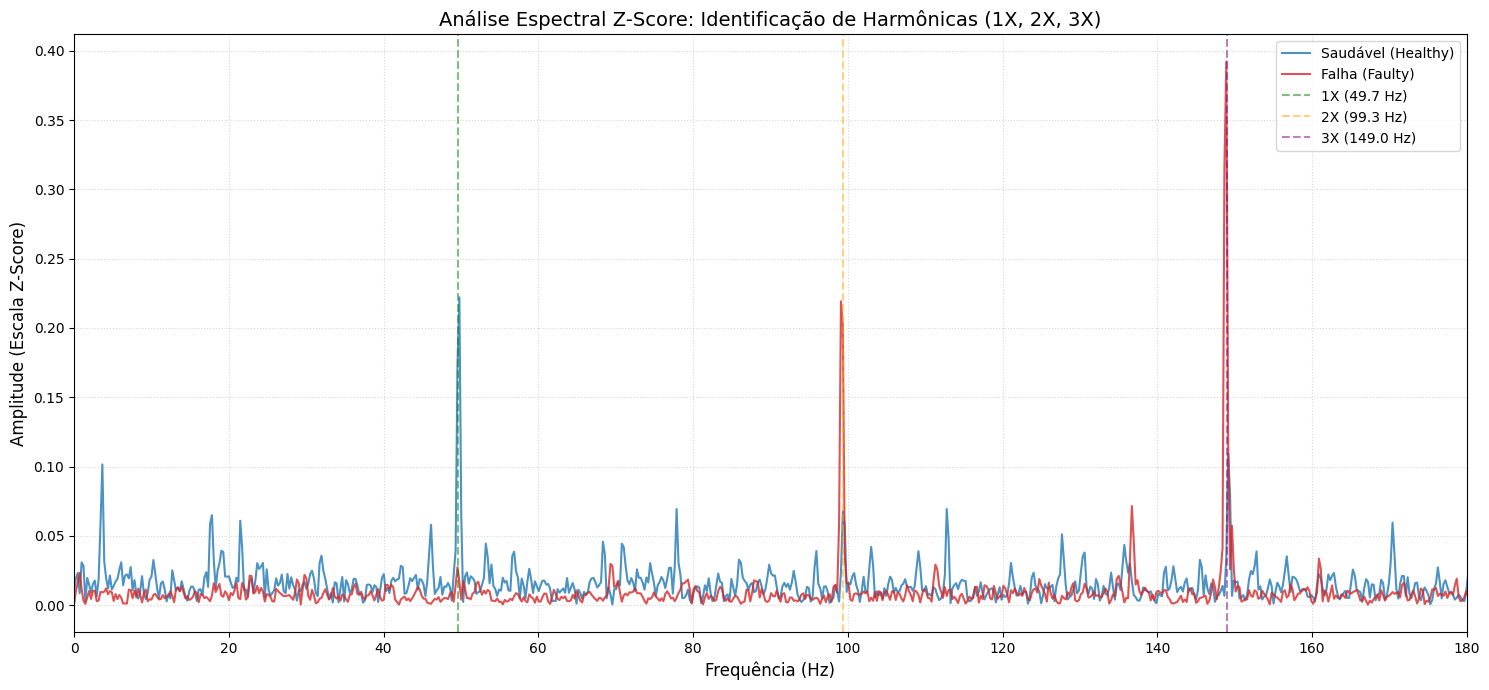

In [ ]:
def gerar_grafico_espectral_artigo_zscore(path_h, path_f, fs=1000, rpm=2980):
    plt.figure(figsize=(15, 7))
    f_rotacao_teorica = rpm / 60
    scaler = StandardScaler()

    print("="*60)
    print("      EXTRAÇÃO DE VALORES: ANÁLISE ESPECTRAL (HARMÔNICAS)")
    print("="*60)

    for caminho, rotulo, color in [(path_h, 'Saudável (Healthy)', '#1f77b4'),
                                   (path_f, 'Falha (Faulty)', '#d62728')]:
        # Extract filename for printing
        filename = os.path.basename(caminho)

        # 1. Carregar e Processar
        mat = loadmat(caminho)
        chave = [k for k in mat.keys() if not k.startswith('__')][0]
        sinal_bruto = mat[chave]
        if sinal_bruto.shape[0] < sinal_bruto.shape[1]: sinal_bruto = sinal_bruto.T

        # Resultante Euclidiana Bruta
        res = np.sqrt(np.sum(sinal_bruto**2, axis=1))

        # 2. Aplicar StandardScaler (Z-Score)
        res_zscore = scaler.fit_transform(res.reshape(-1, 1)).flatten()

        # 3. Cálculo da FFT
        N = 4096
        yf = fft(res_zscore[:N] * np.hanning(N))
        #yf = fft((res - np.mean(res))[:N] * np.hanning(N))
        xf = fftfreq(N, 1/fs)

        amplitude = 2.0/N * np.abs(yf[:N//2])
        frequencias = xf[:N//2]

        # --- BUSCA AUTOMÁTICA DE PICOS REAIS (CAPTURA DO ESCORREGAMENTO) ---
        print(f"CONDIÇÃO: {rotulo} ({filename})")
        for h in [1, 2, 3]:
            f_alvo = h * f_rotacao_teorica
            # Busca o pico real em uma janela de +/- 2Hz ao redor da teórica
            mask = (frequencias >= f_alvo - 2) & (frequencias <= f_alvo + 2)
            if any(mask):
                amp_pico = np.max(amplitude[mask])
                freq_pico = frequencias[mask][np.argmax(amplitude[mask])]
                print(f"-> Harmônica {h}X: Pico Real em {freq_pico:>5.1f} Hz | Amplitude: {amp_pico:.4f} σ")
        print("-" * 60)

        plt.plot(frequencias, amplitude, label=rotulo, color=color, lw=1.5, alpha=0.8)

    # 4. Formatação Estética
    plt.title("Análise Espectral Z-Score: Identificação de Harmônicas (1X, 2X, 3X)", fontsize=14)
    plt.xlabel("Frequência (Hz)", fontsize=12)
    plt.ylabel("Amplitude (Escala Z-Score)", fontsize=12)
    plt.xlim(0, 180)

   # Marcações Técnicas de Harmônicas
    plt.axvline(f_rotacao_teorica, color='green', linestyle='--', alpha=0.5, label=f'1X ({f_rotacao_teorica:.1f} Hz)')
    plt.axvline(2*f_rotacao_teorica, color='orange', linestyle='--', alpha=0.5, label=f'2X ({2*f_rotacao_teorica:.1f} Hz)')
    plt.axvline(3*f_rotacao_teorica, color='purple', linestyle='--', alpha=0.5, label=f'3X ({3*f_rotacao_teorica:.1f} Hz)')

    plt.legend(loc='upper right')
    plt.grid(True, which='both', linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Executa a função
gerar_grafico_espectral_artigo_zscore(healthy_sample, faulty_sample)

# 3.3.b Análise do Domínio da Frequência

## Entrada: Todos os arquivos brutos com sinais temporais triaxiais
## Saída: Sinais de frequencia de cada um dos arquivos

Ao sobrepor os espectros de frequência de todos os 220 registros coletados (Figura 6) em um único gráfico com os eixos das variáveis frequência e amplitude, a distinção entre os estados operacionais torna-se mais evidente através do comportamento das amplitudes harmônicas.

Enquanto os registros da condição “Saudável” (em azul) apresentam um perfil estável e de baixa amplitude, os sinais correspondentes ao estado “Falha” (em vermelho) mostram um aumento de energia em zonas específicas, como em torno dos 100 Hz, que corresponde à segunda harmônica (2X), e também por volta dos 150 Hz, correspondente à terceira harmônica (3X).

Esse acúmulo de energia ao redor das harmônicas funciona como um marcador de diagnóstico. Assim, a análise espectral fornece características importantes, como a amplitude de frequência necessárias para que o classificador identifique padrões de defeito com acurácia.

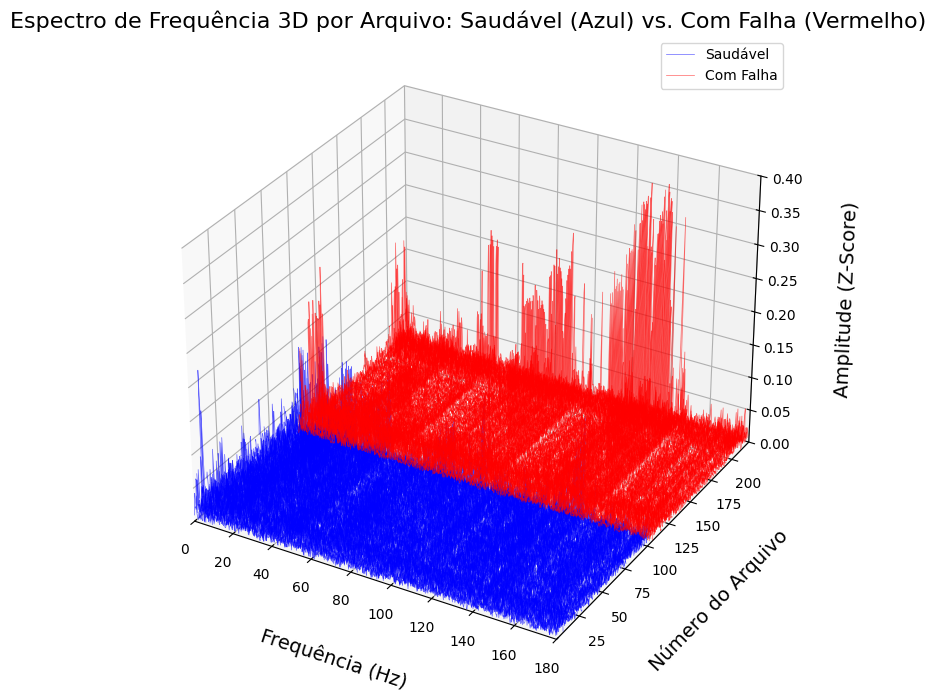

In [ ]:
def plot_3d_frequency_spectrum_all_files(base_path, fs=1000):
    fig = plt.figure(figsize=(15,7))
    ax = fig.add_subplot(111, projection='3d')

    file_counter = 0 # Contador sequencial para indexar a posição de cada arquivo no eixo Y

    # Containers para armazenamento dos espectros processados
    healthy_data = [] # Lista para tuplas (frequência, amplitude, índice) da classe Saudável
    faulty_data = []  # Lista para tuplas (frequência, amplitude, índice) da classe Com Falha

    # --- PROCESSAMENTO DOS ARQUIVOS DA CLASSE SAUDÁVEL (HEALTHY) ---
    healthy_dir = os.path.join(base_path, "Healthy")
    healthy_files = [f for f in os.listdir(healthy_dir) if f.endswith('.mat')]
    healthy_files.sort() # Ordenação alfabética para garantir consistência no eixo Y

    # ESTRUTURA DE REPETIÇÃO (FOR): Itera sobre a fatia definida de arquivos saudáveis
    for arq in healthy_files[:219]:
        file_path = os.path.join(healthy_dir, arq)
        mat = loadmat(file_path)
        chave = [k for k in mat.keys() if not k.startswith('__')][0]
        sinal_bruto = mat[chave]

        # ESTRUTURA CONDICIONAL (IF): Ajusta a orientação espacial da matriz caso necessário
        if sinal_bruto.shape[0] < sinal_bruto.shape[1]:
            sinal_bruto = sinal_bruto.T

        # Cálculo da Resultante Euclidiana Bruta (Soma vetorial multieixo)
        res = np.sqrt(np.sum(sinal_bruto**2, axis=1))

        # Aplicação de padronização estatística Z-Score para viabilizar comparações de amplitude
        scaler = StandardScaler()
        res_zscore = scaler.fit_transform(res.reshape(-1, 1)).flatten()

        # Análise Espectral via FFT com Janelamento para mitigação de vazamento espectral
        N = 4096
        yf = fft(res_zscore[:N] * np.hanning(N)) # Multiplicação pela janela de Hanning
        xf = fftfreq(N, 1/fs)
        amplitude = 2.0/N * np.abs(yf[:N//2]) # Conversão para espectro unilateral de amplitude
        frequencias = xf[:N//2]

        # Filtragem da banda passante de interesse até 180 Hz
        mask = frequencias <= 180
        frequencias_filtered = frequencias[mask]
        amplitude_filtered = amplitude[mask]

        healthy_data.append((frequencias_filtered, amplitude_filtered, file_counter))
        file_counter += 1

    # --- PROCESSAMENTO DOS ARQUIVOS DA CLASSE COM FALHA (FAULTY) ---
    faulty_dir = os.path.join(base_path, "Faulty")
    faulty_files = [f for f in os.listdir(faulty_dir) if f.endswith('.mat')]
    faulty_files.sort() # Ordenação alfabética para garantir consistência no eixo Y

    # ESTRUTURA DE REPETIÇÃO (FOR): Itera sobre a fatia definida de arquivos com defeito
    for arq in faulty_files[:219]:
        file_path = os.path.join(faulty_dir, arq)
        mat = loadmat(file_path)
        chave = [k for k in mat.keys() if not k.startswith('__')][0]
        sinal_bruto = mat[chave]

        # ESTRUTURA CONDICIONAL (IF): Ajusta a orientação espacial da matriz caso necessário
        if sinal_bruto.shape[0] < sinal_bruto.shape[1]:
            sinal_bruto = sinal_bruto.T

        # Cálculo da Resultante Euclidiana Bruta (Soma vetorial multieixo)
        res = np.sqrt(np.sum(sinal_bruto**2, axis=1))

        # Aplicação de padronização estatística Z-Score para viabilizar comparações de amplitude
        scaler = StandardScaler()
        res_zscore = scaler.fit_transform(res.reshape(-1, 1)).flatten()

        # Análise Espectral via FFT com Janelamento para mitigação de vazamento espectral
        N = 4096
        yf = fft(res_zscore[:N] * np.hanning(N))
        xf = fftfreq(N, 1/fs)
        amplitude = 2.0/N * np.abs(yf[:N//2])
        frequencias = xf[:N//2]

        # Filtragem da banda passante de interesse até 180 Hz
        mask = frequencias <= 180
        frequencias_filtered = frequencias[mask]
        amplitude_filtered = amplitude[mask]

        faulty_data.append((frequencias_filtered, amplitude_filtered, file_counter))
        file_counter += 1

    # --- CONSTRUÇÃO DO GRÁFICO DE CASCATA (WATERFALL) 3D ---

    # ESTRUTURA DE REPETIÇÃO (FOR): Projeta as linhas espectrais da classe Saudável em azul
    for freq, amp, file_idx in healthy_data:
        file_idx_array = np.full_like(freq, file_idx + 1) # Transforma o índice em vetor (baseado em 1 para exibição)
        ax.plot(freq, file_idx_array, amp, color='blue', alpha=0.6, linewidth=0.5, label='Saudável' if file_idx == 0 else "")

    # ESTRUTURA DE REPETIÇÃO (FOR): Projeta as linhas espectrais da classe Com Falha em vermelho
    for freq, amp, file_idx in faulty_data:
        file_idx_array = np.full_like(freq, file_idx + 1) # Transforma o índice em vetor (baseado em 1 para exibição)
        ax.plot(freq, file_idx_array, amp, color='red', alpha=0.6, linewidth=0.5, label='Com Falha' if file_idx == healthy_data[-1][2] + 1 else "")

    # Configurações de espaçamento (labelpad) e fontes das dimensões espaciais
    ax.set_xlabel('Frequência (Hz)', fontsize=14, labelpad=20)
    ax.set_ylabel('Número do Arquivo', fontsize=14, labelpad=20)
    ax.set_zlabel('Amplitude (Z-Score)', fontsize=14, labelpad=20)

    # Definição das fronteiras dos eixos para maximizar a renderização tridimensional
    ax.set_xlim(0, 180) # Banda espectral de interesse
    ax.set_ylim(1, file_counter + 1) # Faixa dinâmica dos índices dos arquivos
    ax.set_zlim(0, 0.4) # Faixa de amplitude ajustada para o espectro em unidades Z-score

    plt.title('Espectro de Frequência 3D por Arquivo: Saudável (Azul) vs. Com Falha (Vermelho)', fontsize=16)
    ax.legend()
    plt.tight_layout()
    plt.show()

# Execução do algoritmo de visualização global
plot_3d_frequency_spectrum_all_files(path)

# 3.4 Extração dos Atributos

## Domínio do Tempo:
### * RMS (Root Mean Square):
### * Curtose:
### * Fator de Crista:

## Domínio da Frequência (FFT):
### * Amplitudes Harmônicas (1X, 2X e 3X):

# DADOS
## * Entrada: Arquivos Brutos
## * Saída: Dataset Normalizado (euclidiana)

A etapa de extração de atributos consolidou as informações temporais e de frequência em um conjunto de dados estruturado, permitindo analisar os atributos de forma tabular (Tabela 2). Os dados revelam que variáveis temporais, calculadas a partir da Resultante Euclidiana, como o RMS e o Fator de Crista apresentam uma dispersão controlada, com médias de 1,7275 e 2,3863 e desvio padrão de 0,1162 e 0,5423, respectivamente. No entanto, a análise estatística identifica que a Curtose possui uma variabilidade significativamente maior, atingindo um valor máximo de 5,3450 com desvio padrão de 0,8964 frente a uma média de apenas 0,3147, o que evidencia a presença de amostras com transientes de impacto muito acima da normalidade.

No domínio da frequência, a extração das amplitudes em 1X, 2X e 3X capturou a distribuição de energia característica de máquinas rotativas. A análise dos valores máximos extraídos (0,1942, 0,1574 e 0,2265, respectivamente para 1X, 2X e 3X) confirma a predominância de componentes vibratórias em múltiplos da rotação nominal, fornecendo ao modelo as coordenadas necessárias para a separação de classes. O fato da média da amplitude (0,0955) e do desvio padrão da amplitude em 3X (0,0640) serem os mais elevados entre os atributos no domínio da frequência corrobora que esta harmônica atua como um divisor sensível entre os estados “Saudável” e “Falha”.

Conclui-se que a extração de atributos que transforma sinais temporais em valores estatísticos fornece uma base de dados que já indica, numericamente, diferenças entre as condições operacionais antes mesmo do ajuste de escala final.

In [ ]:
def extrair_features(sinal, fs=1000, rpm=2980):
    """
    Extrai características estatísticas e espectrais.
    O sinal de entrada deve ser a resultante bruta para preservar a física.
    """
    features = {}
    f_rotacao = rpm / 60  # Fundamental (1X) ~49Hz

    # --- Domínio do Tempo (Indicadores Estatísticos de Impacto e Energia) ---
    features['rms'] = np.sqrt(np.mean(sinal**2))
    features['curtose'] = pd.Series(sinal).kurtosis()
    features['fator_crista'] = np.max(np.abs(sinal)) / features['rms']

    # --- Domínio da Frequência (Transformada Rápida de Fourier - FFT) ---
    N = 4096
    sinal_janelado = sinal[:N] * np.hanning(N)
    yf = fft(sinal_janelado)
    xf = fftfreq(N, 1/fs)

    amplitude = 2.0/N * np.abs(yf[:N//2])
    frequencias = xf[:N//2]

    # --- Janelas de Tolerância Espectral para Frequências de Rotação (1X, 2X e 3X) ---
    idx_1x = np.where((frequencias > f_rotacao - 3) & (frequencias < f_rotacao + 3))[0]
    idx_2x = np.where((frequencias > (2*f_rotacao) - 3) & (frequencias < (2*f_rotacao) + 3))[0]
    idx_3x = np.where((frequencias > (3*f_rotacao) - 3) & (frequencias < (3*f_rotacao) + 3))[0]

    # ESTRUTURAS CONDICIONAIS EM LINHA (IF/ELSE): Extraem o pico máximo de amplitude se a janela contiver pontos; caso contrário, retorna 0
    features['amp_1x'] = np.max(amplitude[idx_1x]) if len(idx_1x) > 0 else 0
    features['amp_2x'] = np.max(amplitude[idx_2x]) if len(idx_2x) > 0 else 0
    features['amp_3x'] = np.max(amplitude[idx_3x]) if len(idx_3x) > 0 else 0

    return features

# --- Reprocessamento Global e Estruturação do Dataset ---
dados_finais = []

# LAÇO DE REPETIÇÃO (FOR): Itera pelas classes de condições de operação do motor ('Healthy' e 'Faulty')
for classe in ['Healthy', 'Faulty']:
    pasta = os.path.join(path, classe)
    arquivos = [f for f in os.listdir(pasta) if f.endswith('.mat')]

    # LAÇO DE REPETIÇÃO (FOR): Itera por cada arquivo .mat localizado dentro da pasta da classe atual
    for arq in arquivos:
        mat = loadmat(os.path.join(pasta, arq))
        chave = [k for k in mat.keys() if not k.startswith('__')][0]
        sinal_bruto = mat[chave]

        # ESTRUTURA CONDICIONAL (IF): Valida o formato da matriz e corrige a orientação caso as amostras estejam nas linhas
        if sinal_bruto.shape[0] < sinal_bruto.shape[1]:
            sinal_bruto = sinal_bruto.T

        # 1. Resultante Euclidiana BRUTA (Soma vetorial dos eixos para preservação da energia)
        res = np.sqrt(np.sum(sinal_bruto**2, axis=1))

        # 2. Extração de características (Processamento espectro-temporal no sinal original)
        feat = extrair_features(res, rpm=2980) # RPM padronizado conforme discussão

        # ESTRUTURA CONDICIONAL EM LINHA (IF/ELSE): Define a variável alvo (Target) sendo 0 para Saudável e 1 para Falha
        feat['target'] = 0 if classe == 'Healthy' else 1
        dados_finais.append(feat)

# 3. Construção do DataFrame Consolidado
df_treino = pd.DataFrame(dados_finais)

print("\n" + "="*50)
print("DATASET NORMALIZADO COM 220 AMOSTRAS")
print("="*50)
print(df_treino.describe().round(4))




DATASET NORMALIZADO COM 220 AMOSTRAS
            rms   curtose  fator_crista    amp_1x    amp_2x    amp_3x  \
count  220.0000  220.0000      220.0000  220.0000  220.0000  220.0000   
mean     1.7275    0.3147        2.3863    0.0703    0.0682    0.0955   
std      0.1162    0.8964        0.5423    0.0521    0.0390    0.0640   
min      1.4806   -0.4443        1.6919    0.0094    0.0138    0.0122   
25%      1.6919   -0.1996        1.7825    0.0227    0.0338    0.0403   
50%      1.7302   -0.0020        2.4492    0.0554    0.0581    0.0764   
75%      1.7503    0.3795        2.6812    0.1062    0.0998    0.1503   
max      2.7401    5.3450        5.0584    0.1942    0.1574    0.2265   

         target  
count  220.0000  
mean     0.5318  
std      0.5001  
min      0.0000  
25%      0.0000  
50%      1.0000  
75%      1.0000  
max      1.0000  


# 3.5 Tratamento de “Outliers” e Limpeza de Dados
# Cálculo dos Quartis do RMS
## Entrada: Dataset Normalizado
## Saída: Boxplot

A integridade do diagnóstico automatizado depende da qualidade das amostras de treinamento, o que exigiu a identificação e remoção de *outliers* (Figura 7). Para este fim, utilizou-se o método da Amplitude Interquartílica (IQR) sobre o *dataset* normalizado, estabelecendo limites para a exclusão de amostras espúrias (Tabela 3).

A escolha do RMS como a variável de referência para o corte crítico justifica-se por sua natureza física: o RMS é o indicador mais direto da energia eficaz vibratória. Ao observar os gráficos de *boxplot* de todos os atributos (Figura 8), nota-se que enquanto atributos como a Curtose, Fator de Crista e as amplitudes harmônicas possuem uma variabilidade intrínseca associada à falha, o RMS apresenta uma distribuição mais centrada no estado “Saudável”.

A aplicação do filtro com IQR resultou na exclusão de 7 amostras do grupo “Saudável” que excederam o limite superior de 1,8520 (Tabela 3), consolidando um *dataset* final de 213 amostras balanceadas (Tabela 4). Decidiu-se preservar todos os dados do estado de falha devido à relevância física do comportamento de falha. Enquanto no estado íntegro os *outliers* indicam ruídos espúrios que devem ser removidos para evitar alarmes falsos, na classe de falha as flutuações extremas representam a manifestação física real do defeito mecânico. Portanto, eliminar estes pontos comprometeria a representatividade do conjunto de dados de treino. A manutenção destes transientes garante que o classificador KNN reconheça as falhas severas em operação.

A análise comparativa das estatísticas antes (Tabela 2) e após a limpeza (Tabela 5) revela que os atributos tanto do domínio do tempo como da frequência foram praticamente preservados, com variações pequenas, para manter a sensibilidade ao defeito.

/tmp/ipykernel_1542/1065986545.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='rms', y='target', data=df, orient='h', palette=cores)


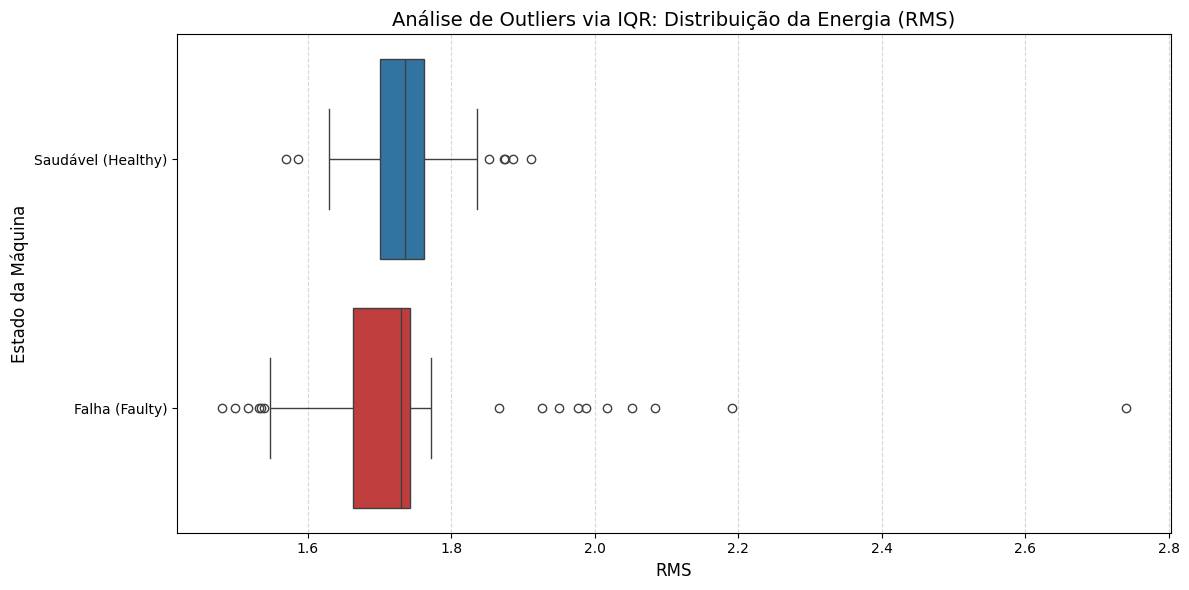

--- VALORES DOS QUARTIS ---
Classe Saudável:
  Q1: 1.7004 | Q3: 1.7610
  IQR: 0.0606 | Limite Superior: 1.8520

Classe Falha:
  Q1: 1.6634 | Q3: 1.7421
  IQR: 0.0787 | Limite Superior: 1.8602



In [ ]:
def analise_investigativa_outliers_horizontal(df):
    # --- CONFIGURAÇÃO GRÁFICA DO BOXPLOT HORIZONTAL ---
    plt.figure(figsize=(12, 6))

    # Definindo mapeamento cromático para as classes (chaves em formato string para compatibilidade com o Seaborn)
    cores = {'0': '#1f77b4', '1': '#d62728'}

    # Renderização do Boxplot horizontal orientado por classes para análise de dispersão e outliers
    sns.boxplot(x='rms', y='target', data=df, orient='h', palette=cores)

    # Customização dos rótulos do eixo Y para representação correta das categorias diagnósticas
    plt.yticks([0, 1], ['Saudável (Healthy)', 'Falha (Faulty)'])

    plt.title("Análise de Outliers via IQR: Distribuição da Energia (RMS)", fontsize=14)
    plt.xlabel("RMS", fontsize=12)
    plt.ylabel("Estado da Máquina", fontsize=12)

    # Ativação das linhas de grade verticais para otimizar a leitura das amplitudes estatísticas no eixo horizontal
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # --- CÁLCULO E EXTRAÇÃO DOS LIMITES ESTATÍSTICOS (MÉTODO IQR) ---
    print("--- VALORES DOS QUARTIS ---")

    # ESTRUTURA DE REPETIÇÃO (FOR): Itera sobre os identificadores numéricos das classes alvo (0 para Saudável e 1 para Falha)
    for t in [0, 1]:
        # ESTRUTURA CONDICIONAL TERNÁRIA (IF/ELSE): Define a string de rótulo textual baseada no valor inteiro da classe
        label = 'Falha' if t==1 else 'Saudável'

        # Filtra e isola os dados de energia (RMS) estritamente pertencentes à classe atual da iteração
        dados = df[df['target'] == t]['rms']

        # Determinação do Primeiro Quartil (25%), Terceiro Quartil (75%) e do Intervalo Interquartil (IQR)
        q1 = dados.quantile(0.25)
        q3 = dados.quantile(0.75)
        iqr = q3 - q1

        # Cálculo do limite superior para identificação de outliers à direita (critério clássico de Tukey)
        limite_superior = q3 + 1.5 * iqr

        print(f"Classe {label}:")
        print(f"  Q1: {q1:.4f} | Q3: {q3:.4f}")
        print(f"  IQR: {iqr:.4f} | Limite Superior: {limite_superior:.4f}\n")

# Execução da rotina de análise estatística descritiva e de outliers
analise_investigativa_outliers_horizontal(df_treino)

# Cálculo de IQR e Remoção dos Outliers
## Entrada: Dataset Normalizado
## Saída: Dataset Normalizado (eucliadiana) e Limpo (sem outliers)

In [ ]:
# 1. Separar os grupos para análise isolada
df_healthy = df_treino[df_treino['target'] == 0].copy()
df_faulty = df_treino[df_treino['target'] == 1].copy()

print("="*50)
print("ESTATÍSTICAS DOS QUARTIS DO GRUPO SAUDÁVEL")
print("="*50)
# 2. Calcular IQR apenas para o grupo Saudável (Referência de Normalidade)
Q1_h = df_healthy['rms'].quantile(0.25)
Q3_h = df_healthy['rms'].quantile(0.75)
IQR_h = Q3_h - Q1_h

# Definição dos limites de Tukey
limite_inferior_h = Q1_h - 1.5 * IQR_h
limite_superior_h = Q3_h + 1.5 * IQR_h

print(f"Q1 (25%):        {Q1_h:.4f}")
print(f"Q3 (75%):        {Q3_h:.4f}")
print(f"IQR:             {IQR_h:.4f}")
print("-"*50)
print(f"Limite Inferior: {limite_inferior_h:.4f}")
print(f"Limite Superior: {limite_superior_h:.4f}")

# 3. Filtrar APENAS o grupo saudável
df_healthy_clean = df_healthy[(df_healthy['rms'] >= limite_inferior_h) &
                              (df_healthy['rms'] <= limite_superior_h)]

print("="*50)
print("ESTATÍSTICAS DOS QUARTIS DO GRUPO FALHA")
print("="*50)
# Calcular IQR para o grupo Falha
Q1_f = df_faulty['rms'].quantile(0.25)
Q3_f = df_faulty['rms'].quantile(0.75)
IQR_f = Q3_f - Q1_f

# Definição dos limites de Tukey
limite_inferior_f = Q1_f - 1.5 * IQR_f
limite_superior_f = Q3_f + 1.5 * IQR_f

print(f"Q1 (25%):        {Q1_f:.4f}")
print(f"Q3 (75%):        {Q3_f:.4f}")
print(f"IQR:             {IQR_f:.4f}")
print("-"*50)
print(f"Limite Inferior: {limite_inferior_f:.4f}")
print(f"Limite Superior: {limite_superior_f:.4f}")

print("="*50)
print("QUANTIDADE DE AMOSTRAS APÓS LIMPEZA")
print("="*50)
print(f"Amostras Saudáveis Originais: {len(df_healthy)}")
print(f"Amostras com Falha Mantidas:  {len(df_faulty)}")
print(f"Amostras Saudáveis Removidas: {len(df_healthy) - len(df_healthy_clean)}")


# 4. Concatenar de volta com o grupo Falha (preservando a sensibilidade à falha)
df_treino_filtrado = pd.concat([df_healthy_clean, df_faulty], axis=0)
print(f"Total Final (Dataset Treino): {len(df_treino_filtrado)}")
print("="*50)

print("\n" + "="*50)
print("DATASET NORMALIZADO E LIMPO COM 213 AMOSTRAS")
print("="*50)
print(df_treino_filtrado.describe().round(4))

ESTATÍSTICAS DOS QUARTIS DO GRUPO SAUDÁVEL
Q1 (25%):        1.7004
Q3 (75%):        1.7610
IQR:             0.0606
--------------------------------------------------
Limite Inferior: 1.6095
Limite Superior: 1.8520
ESTATÍSTICAS DOS QUARTIS DO GRUPO FALHA
Q1 (25%):        1.6634
Q3 (75%):        1.7421
IQR:             0.0787
--------------------------------------------------
Limite Inferior: 1.5453
Limite Superior: 1.8602
QUANTIDADE DE AMOSTRAS APÓS LIMPEZA
Amostras Saudáveis Originais: 103
Amostras com Falha Mantidas:  117
Amostras Saudáveis Removidas: 7
Total Final (Dataset Treino): 213

DATASET NORMALIZADO E LIMPO COM 213 AMOSTRAS
            rms   curtose  fator_crista    amp_1x    amp_2x    amp_3x  \
count  213.0000  213.0000      213.0000  213.0000  213.0000  213.0000   
mean     1.7253    0.3241        2.3831    0.0691    0.0684    0.0967   
std      0.1148    0.9092        0.5503    0.0518    0.0393    0.0646   
min      1.4806   -0.4443        1.6919    0.0094    0.0138    0.01

# Análise gráfica da distribuição estatística com Boxplot dos atributos

## Entrada: Dataset Normalizado

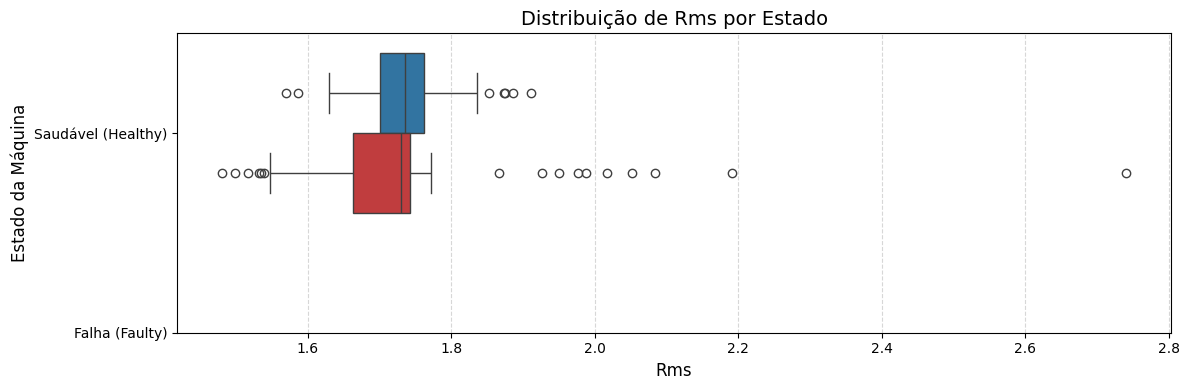

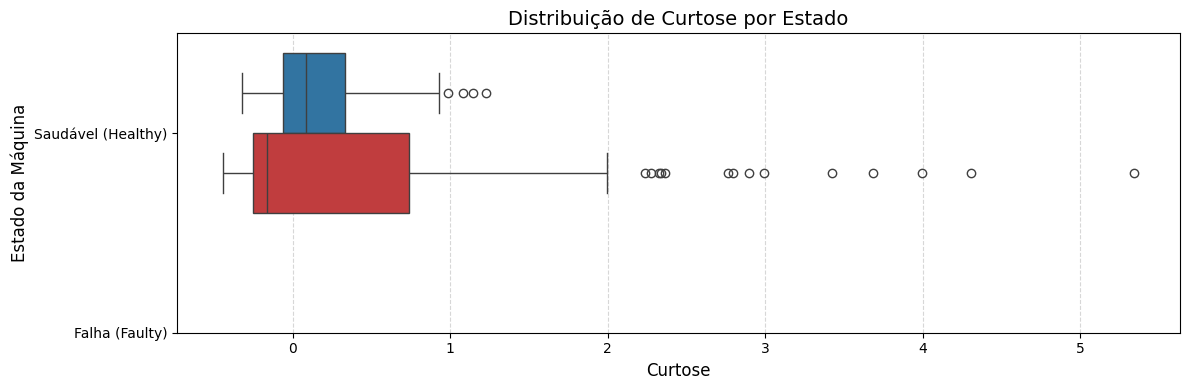

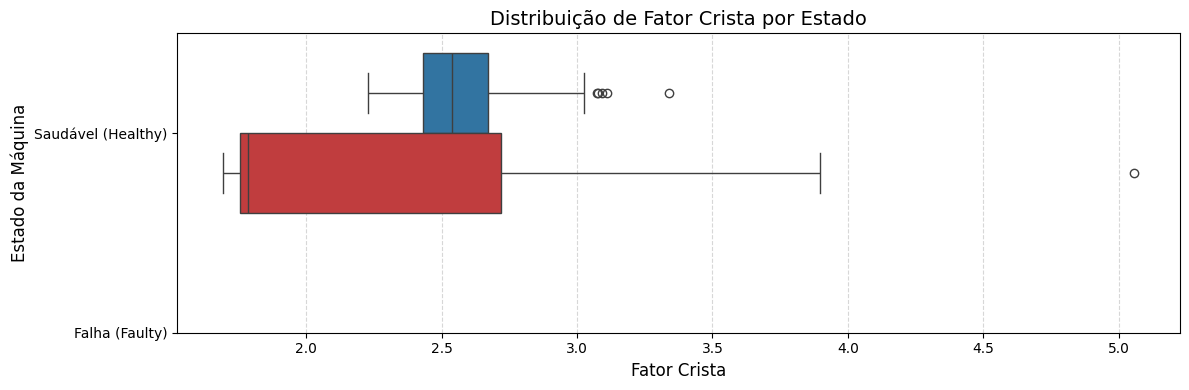

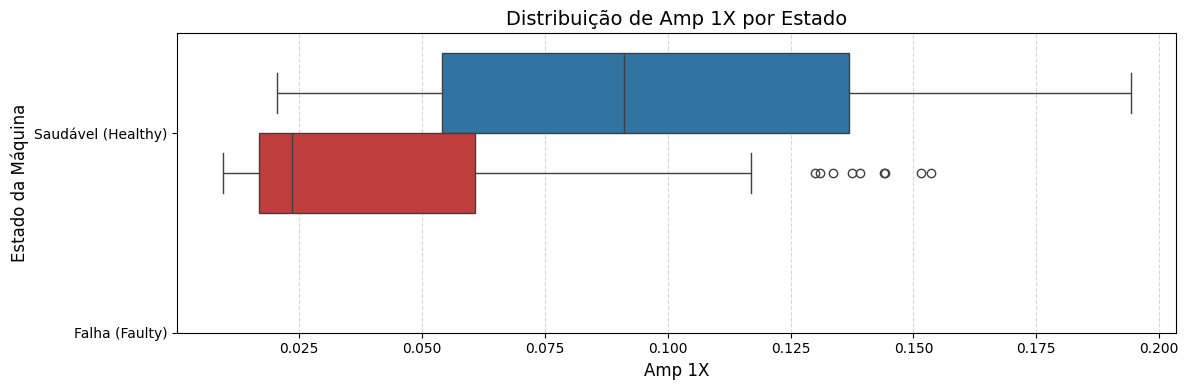

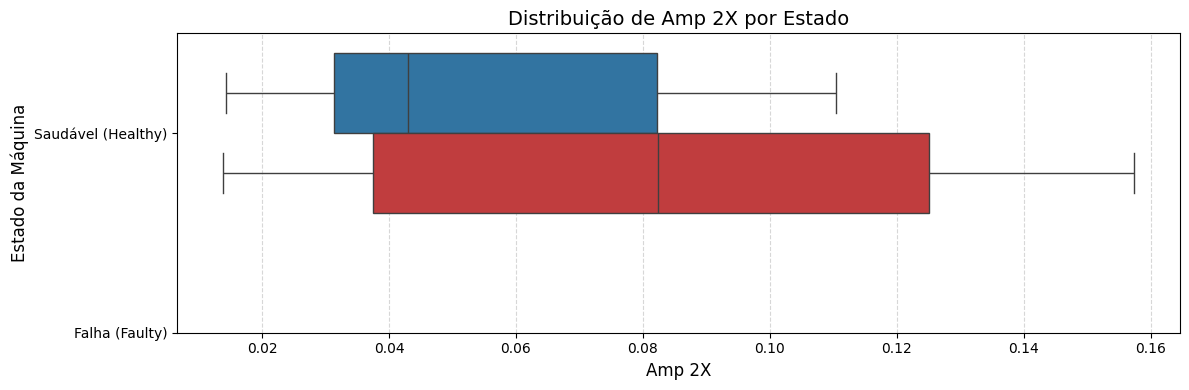

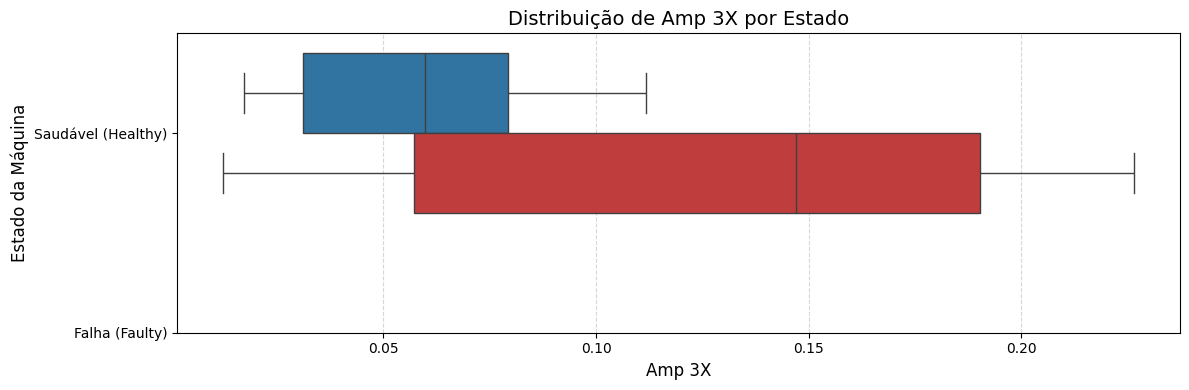

In [ ]:
def plot_feature_boxplots(df):
    features = df.drop('target', axis=1).columns # Get all feature names

    # Define consistent colors and labels
    colors = {0: '#1f77b4', 1: '#d62728'}
    target_labels = {0: 'Saudável (Healthy)', 1: 'Falha (Faulty)'}

    for feature in features:
        # Create a new figure and axes for each feature
        fig, ax = plt.subplots(figsize=(12, 4)) # Adjust figure size for a single plot

        # Plot boxplot
        sns.boxplot(x=feature, hue='target', data=df, orient='h', palette=colors, ax=ax, legend=False)
        ax.set_title(f'Distribuição de {feature.replace("_", " ").title()} por Estado', fontsize=14)
        ax.set_xlabel(f'{feature.replace("_", " ").title()}', fontsize=12)
        ax.set_ylabel('Estado da Máquina', fontsize=12)
        ax.set_yticks([0, 1])
        ax.set_yticklabels([target_labels[0], target_labels[1]])
        ax.grid(axis='x', linestyle='--', alpha=0.5)

        plt.tight_layout()
        plt.show()

# Call the function with the scaled and filtered DataFrame
plot_feature_boxplots(df_treino)

# Escalona o dataset para usar nos gráficos
## Entrada: Dataset Normalizado e Escalonado (não limpo)

In [ ]:
# 4. APLICAÇÃO DO STANDARD SCALER (Onde a mágica acontece)
# Separamos as colunas de dados do target
X = df_treino.drop('target', axis=1)
y = df_treino['target']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Converter de volta para DataFrame para manter os nomes das colunas
df_treino_scaled = pd.DataFrame(X_scaled, columns=X.columns)
df_treino_scaled['target'] = y.values

print("\n" + "="*50)
print("DATASET NORMALIZADO E ESCALONADO COM 220 AMOSTRAS")
print("="*50)
print(df_treino_scaled.describe().round(4))


DATASET NORMALIZADO E ESCALONADO COM 220 AMOSTRAS
            rms   curtose  fator_crista    amp_1x    amp_2x    amp_3x  \
count  220.0000  220.0000      220.0000  220.0000  220.0000  220.0000   
mean    -0.0000    0.0000        0.0000   -0.0000    0.0000    0.0000   
std      1.0023    1.0023        1.0023    1.0023    1.0023    1.0023   
min     -2.1292   -0.8487       -1.2834   -1.1702   -1.3964   -1.3049   
25%     -0.3065   -0.5751       -1.1159   -0.9151   -0.8821   -0.8656   
50%      0.0230   -0.3541        0.1162   -0.2870   -0.2595   -0.2990   
75%      0.1966    0.0725        0.5449    0.6909    0.8120    0.8584   
max      8.7339    5.6245        4.9381    2.3836    2.2903    2.0522   

         target  
count  220.0000  
mean     0.5318  
std      0.5001  
min      0.0000  
25%      0.0000  
50%      1.0000  
75%      1.0000  
max      1.0000  


# 3.6 Análise Estatística da Função Densidade de Probabilidade (PDF)
## Entrada: Dataset Normalizado e Escalonado (não limpo)

A análise da PDF (Figura 9) revela a separação clara entre os comportamentos dos estados operacionais. Analisando o *dataset* normalizado e escalonado, nota-se que enquanto a distribuição do grupo “Saudável” apresenta uma concentração simétrica e estreita em torno da média, indicando um regime de vibração estável e previsível, a distribuição do grupo “Falha” exibe uma base significativamente mais larga e uma cauda longa à direita. Esse comportamento é quantificado pela discrepância acentuada na Curtose.

O estado “Saudável” tem Curtose com valor de 0,8227 (Tabela 6), enquanto o estado “Falha” mostra Curtose de 17,9942 (Tabela 6). Esse valor elevado na curtose do estado “Falha” comprova que a anomalia mecânica não apenas eleva a energia média, mas introduz uma alteração do comportamento da vibração que deforma a normalidade do sinal. A análise da amplitude total, que salta de 2,9503 no estado “Saudável” para 10,8631 na “Falha” (Tabela 6), comprova que o domínio do tempo, quando analisado sob a ótica da probabilidade, já oferece respaldo numérico para a tomada de decisão do modelo para separar as classes “Saudável” e “Falha”.

A elevada Curtose de 17,9942 (Tabela 6) da “Falha” corrobora a dispersão de dados visualizada anteriormente no gráfico de *boxplot* do RMS (Figura 7). Isso demonstra que as amostras com maior RMS são as mesmas que apresentam vibrações de impactos severos, justificando o uso do IQR sobre o RMS como parâmetro para identificação de *outliers* e para a limpeza do *dataset*.

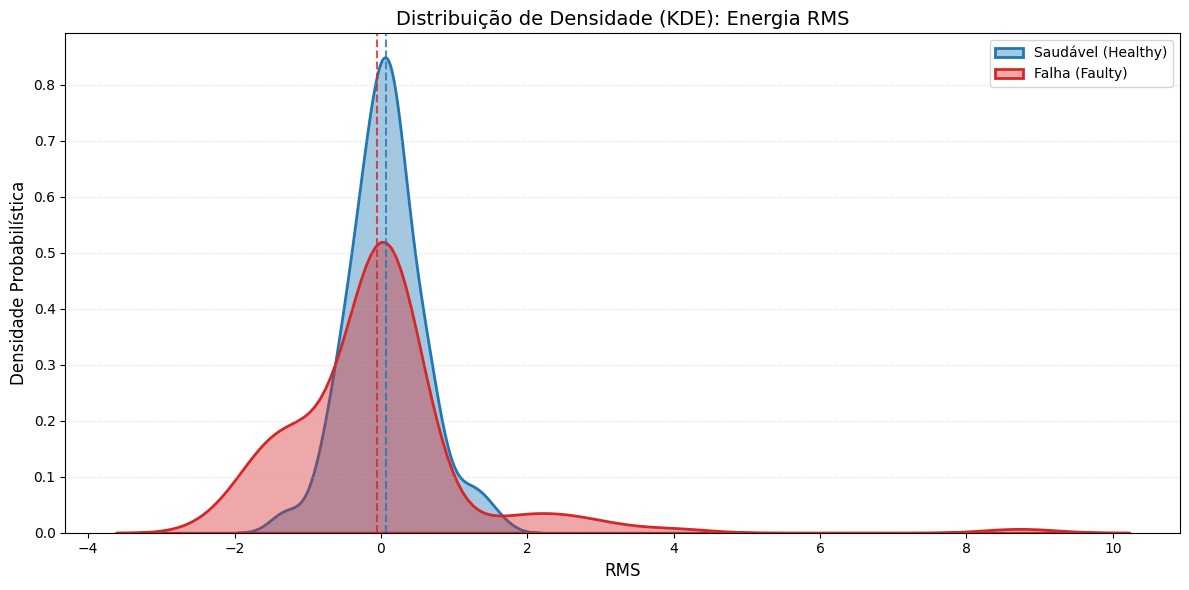

In [ ]:
def plotar_distribuicao_rms_estatistica(df):
    plt.figure(figsize=(12, 6))

    # Cores consistentes com o restante do artigo
    cores = {0: '#1f77b4', 1: '#d62728'}
    labels = {0: 'Saudável (Healthy)', 1: 'Falha (Faulty)'}

    # Plotagem das curvas de densidade (KDE)
    for target, cor in cores.items():
        sns.kdeplot(data=df[df['target'] == target], x='rms',
                    fill=True, color=cor, label=labels[target],
                    alpha=0.4, linewidth=2)

    plt.title("Distribuição de Densidade (KDE): Energia RMS", fontsize=14)
    plt.xlabel("RMS", fontsize=12)
    plt.ylabel("Densidade Probabilística", fontsize=12)

    # Adicionando linhas verticais para as médias de cada grupo
    for target, cor in cores.items():
        plt.axvline(df[df['target'] == target]['rms'].mean(),
                    color=cor, linestyle='--', alpha=0.8)

    plt.legend()
    plt.grid(axis='y', linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Execução ESCALONADO
plotar_distribuicao_rms_estatistica(df_treino_scaled)

# Calculo estatistico do RMS
## Entrada: Dataset Normalizado e Escalonado (não limpo)

In [ ]:

from scipy.stats import kurtosis

def analisar_estatisticas_rms(df):
    resultados = []

    for target_val, label in zip([0, 1], ['Saudável', 'Falha']):
        subset = df[df['target'] == target_val]['rms']

        media = subset.mean()
        desvio_padrao = subset.std()
        pico_max = subset.max()
        pico_min = subset.min()
        curtose_val = kurtosis(subset)
        amplitude = pico_max - pico_min

        resultados.append({
            'Estado': label,
            'Média': media,
            'DesvioPadrão': desvio_padrao,
            'PicoMax': pico_max,
            'PicoMin': pico_min,
            'Curtose': curtose_val,
            'Amplitude': amplitude
        })

    df_resultados = pd.DataFrame(resultados)

    print("\n" + "="*70)
    print("                      ANÁLISE DAS ESTATÍSTICAS DA ENERGIA (RMS)")
    print("="*70)
    # Formatando para exibição como no exemplo do usuário
    print(df_resultados.to_string(index=False, float_format=lambda x: f'{x:10.4f}'))
    print("="*70)

# Chamando a função com o DataFrame já escalonado
analisar_estatisticas_rms(df_treino_scaled)


                      ANÁLISE DAS ESTATÍSTICAS DA ENERGIA (RMS)
  Estado      Média  DesvioPadrão    PicoMax    PicoMin    Curtose  Amplitude
Saudável     0.0657        0.5115     1.5855    -1.3648     0.8227     2.9503
   Falha    -0.0578        1.2881     8.7339    -2.1292    17.9942    10.8631


# 3.7 Análise Comparativa das Densidades de Probabilidade dos Atributos
## Entrada: Dataset Normalizado e Escalonado (não limpo)

Analisando as curvas PDF para os demais atributos extraídos, revela-se como a assinatura da falha se manifesta de forma diferenciada para cada um deles. Ao observar as PDF dos atributos (Figura 10) — RMS, Fator de Crista, Curtose e as amplitudes harmônicas (1X, 2X, 3X) —, nota-se que ocorre uma alteração brusca na forma das distribuições de cada atributo, tornando-se mais um elemento de separação entre as classes para o KNN.

Enquanto o grupo “Saudável” apresenta curvas com amplitude elevada e concentradas (exceto para 1X), indicando um comportamento operacional altamente repetitivo e de baixa variância, as curvas do estado “Falha” exibem um achatamento, um alargamento das bases e o prolongamento das caudas. Este fenômeno demonstra que a falha mecânica introduz uma instabilidade estatística que espalha os valores ao longo do eixo, criando características únicas que o KNN utiliza para delimitar suas fronteiras de decisão entre as classes.

No caso das amplitudes harmônicas, a distribuição entre “Saudável” e “Falha” é mais difusa, como no cenário da amplitude 1X, que apresenta a distribuição “Saudável” mais achatada e com base mais longa do que a de “Falha”. Portanto, a análise conjunta das curvas PDF indica que a extração de atributos híbridos (tempo e frequência) oferece grande eficiência, pois, se um atributo apresenta uma zona de incerteza, o outro fornece a segregação necessária.

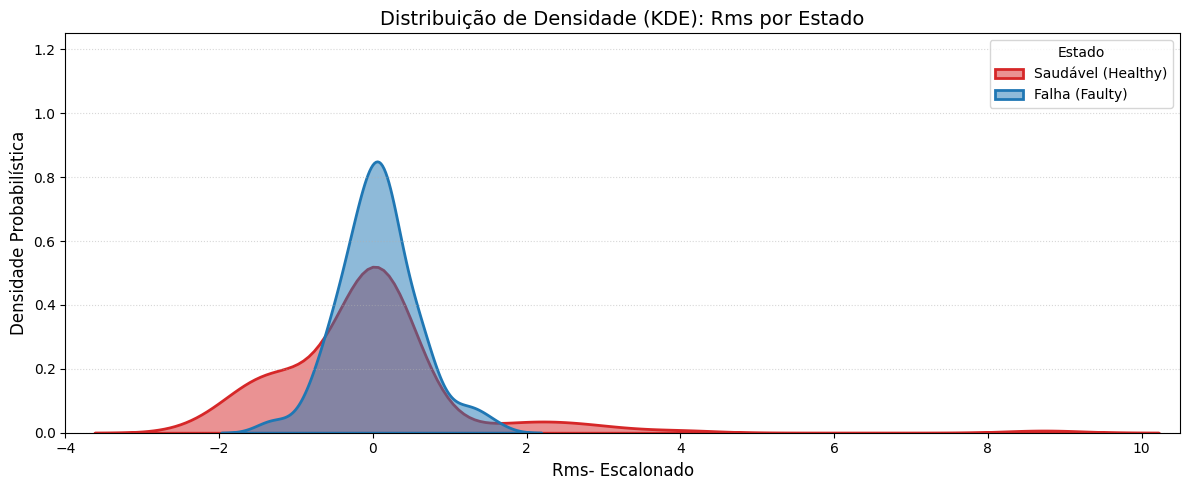

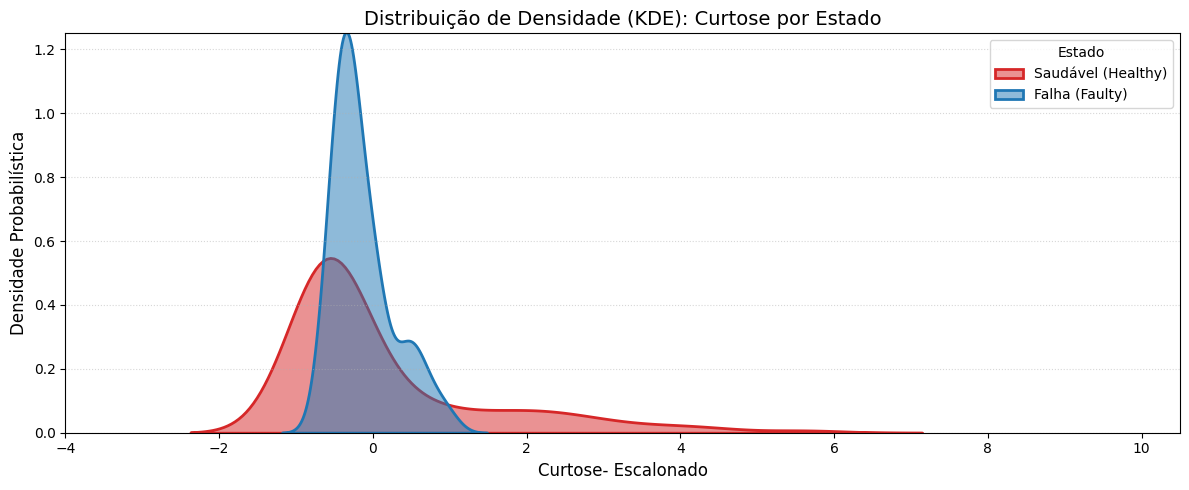

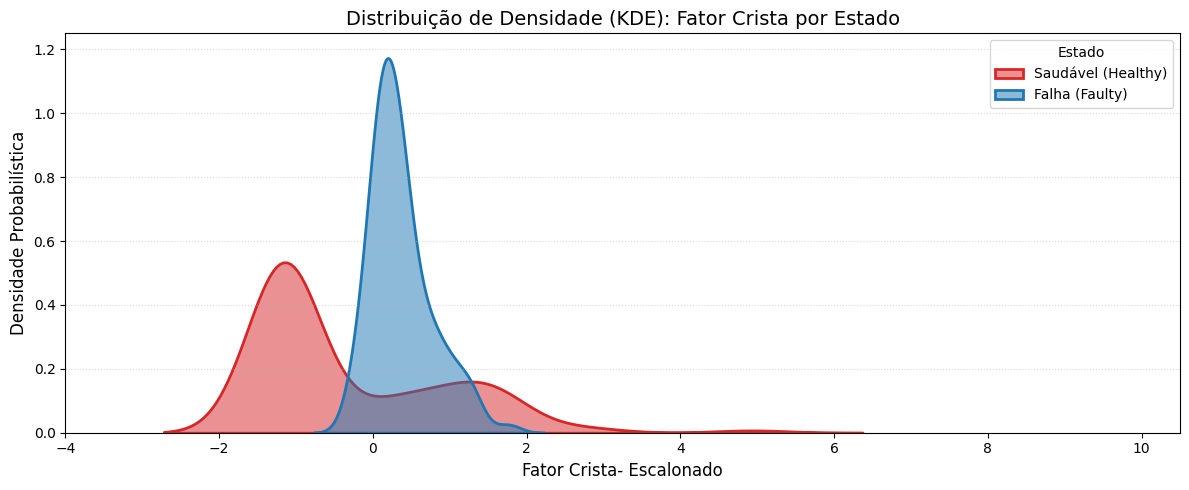

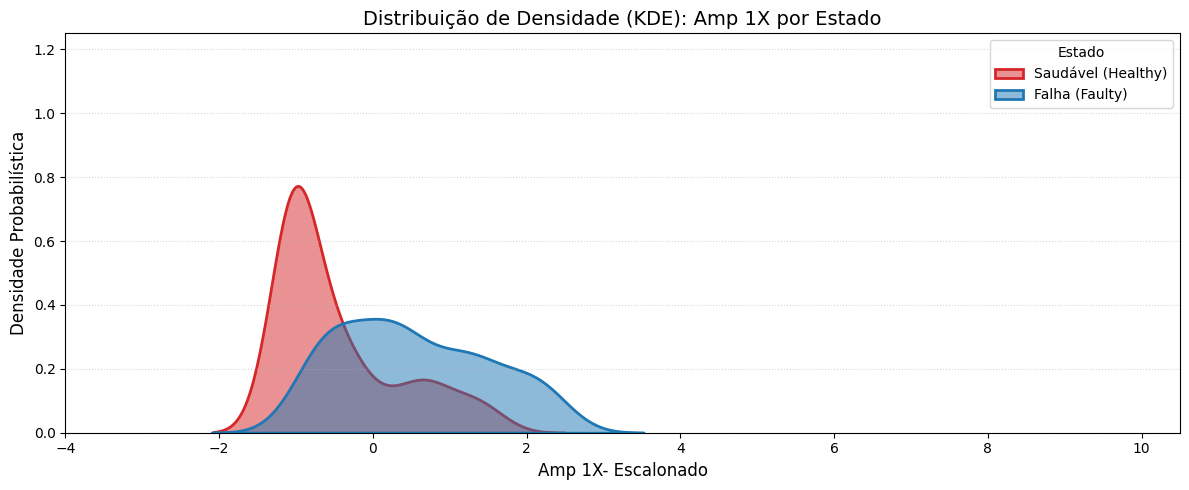

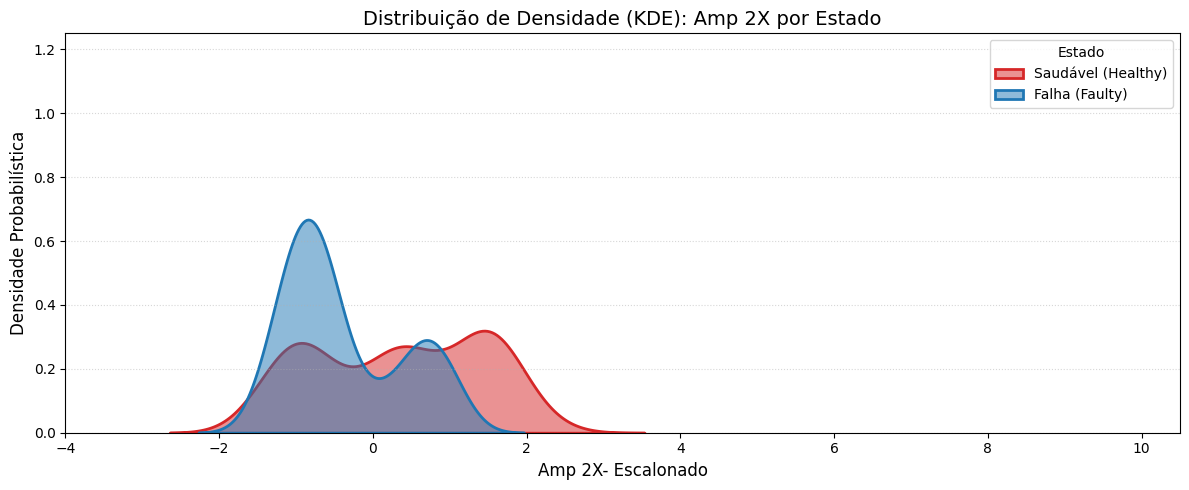

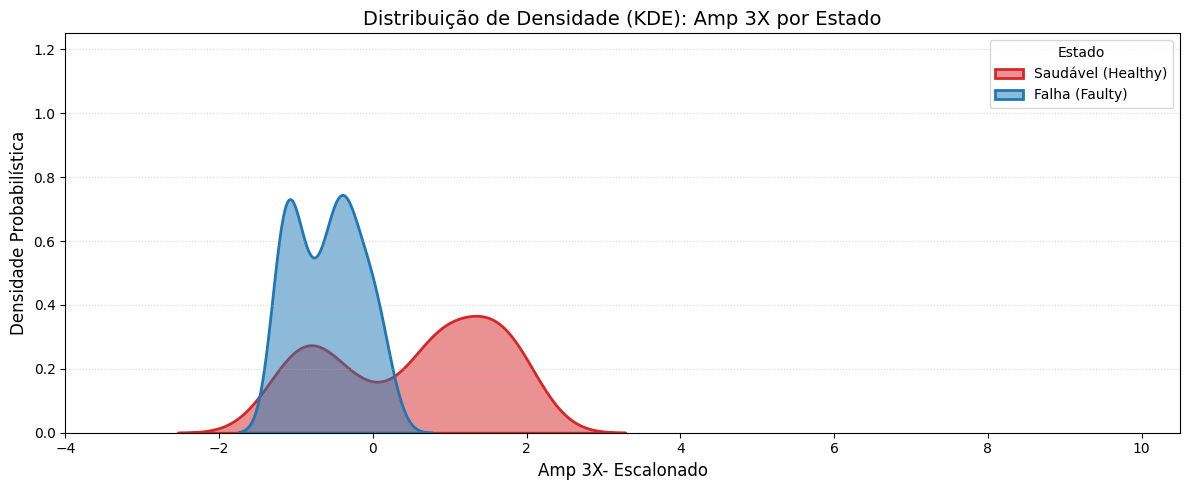

In [ ]:
def plot_feature_kde_comparisons(df):
    # Get all feature names, excluding the 'target' column
    features = df.drop('target', axis=1).columns

    # Define consistent colors and labels
    colors = {0: '#1f77b4', 1: '#d62728'}
    target_labels = {0: 'Saudável (Healthy)', 1: 'Falha (Faulty)'}

    for feature in features:
        # Create a new figure for each feature
        fig, ax = plt.subplots(figsize=(12, 5))

        # Plot KDE for both healthy and faulty conditions on this new figure
        sns.kdeplot(data=df, x=feature, hue='target', fill=True, common_norm=False,
                    palette=colors, ax=ax, alpha=0.5, linewidth=2)

        ax.set_title(f'Distribuição de Densidade (KDE): {feature.replace("_", " ").title()} por Estado', fontsize=14)
        ax.set_xlabel(f'{feature.replace("_", " ").title()}- Escalonado', fontsize=12)
        ax.set_ylabel('Densidade Probabilística', fontsize=12)
        ax.legend(title='Estado', labels=[target_labels[0], target_labels[1]]) # Set legend labels explicitly
        ax.grid(axis='y', linestyle=':', alpha=0.5)
        ax.set_ylim(0, 1.25) # Set y-axis limit to 1.25
        ax.set_xlim(-4,10.5) # Set y-axis limit to 1.25

        plt.tight_layout()
        plt.show()

# Call the function with the scaled and filtered DataFrame
plot_feature_kde_comparisons(df_treino_scaled)

# 3.8 Análise de Correlação dos Atributos de Vibração
## Entrada: Dataset Normalizado e Limpo

A investigação da correlação linear (Figura 11 e Tabela 7) identifica a relevância dos atributos na distinção entre os estados “Saudável” e “Falha”. O coeficiente de correlação ponto-bisserial ($r$) revela que a amplitude na terceira harmônica (`amp_3x`) possui a maior correlação positiva, de 0,5532, consolidando-se como o principal indicador para anomalia mecânica. Por outro lado, observa-se uma correlação negativa expressiva na frequência fundamental (`amp_1x`), de -0,4964.

Este fenômeno indica que, enquanto a energia da falha excita a harmônica superior (`amp_3x`), na harmônica mais baixa (`amp_1x`) há uma relação inversa. Isso torna essa dupla de atributos espectrais uma forte combinação para a distinção entre as classes; ou seja, o alto índice positivo de `amp_3x` aponta o caminho para a anomalia e, no outro extremo, o elevado índice negativo de `amp_1x` leva à normalidade.

O RMS apresentou uma correlação negativa e baixa, de -0,0438, sugerindo que a energia eficaz tem pouca significância no contexto geral. Já o Fator de Crista, de -0,3436, atua com boa significância para a normalidade. No sentido oposto, reforçando a anomalia mecânica, a harmônica `amp_2x` (0,3717) e a Curtose (0,1208) confirmam que a detecção de defeitos mecânicos é complexa e dependente de atributos com comportamentos distintos.

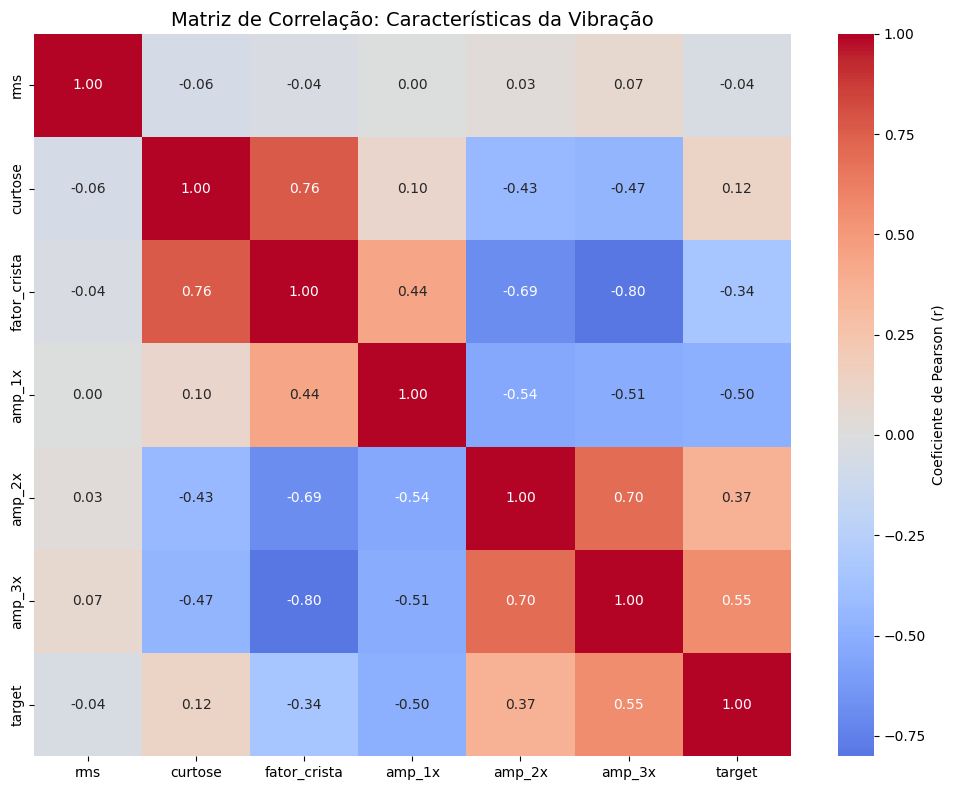

In [ ]:
# --- 1. CÁLCULO DA MATRIZ DE CORRELAÇÃO DE PEARSON ---
# Calcula os coeficientes de correlação linear (r) sobre o DataFrame filtrado
corr = df_treino_filtrado.corr()

# --- 2. CONFIGURAÇÃO E RENDERIZAÇÃO DO HEATMAP (MAPA DE CALOR) ---
plt.figure(figsize=(10, 8))

sns.heatmap(corr,
            annot=True,           # Exibe os coeficientes numéricos em cada célula
            fmt=".2f",            # Arredonda a exibição para duas casas decimais
            cmap='coolwarm',      # Divergência cromática: azul (negativa), branco (neutra) e vermelho (positiva)
            center=0,             # Ancora o ponto médio da escala de cores no valor zero (r = 0)
            cbar_kws={'label': 'Coeficiente de Pearson (r)'})

plt.title("Matriz de Correlação: Características da Vibração", fontsize=14)
plt.tight_layout()
plt.show()

# Correlação dos Atributos - Valores
## Entrada: Dataset Normalizado e Limpo

In [ ]:
# 1. Calcular a correlação especificamente com a coluna 'target'
correlacao_target = df_treino_filtrado.corr()['target'].sort_values(ascending=False)

# 2. Exibição formatada para o artigo
print("="*60)
print("CORRELAÇÃO DOS ATRIBUTOS DE VIBRAÇÃO")
print("="*60)
print(f"{'Feature':<25}  {'Coeficiente (r)':<15}")

for feature, valor in correlacao_target.items():
    # Ignora a própria linha do target para não ser redundante
    if feature != 'target':
        print(f"{feature:<25}  {valor:>15.4f}")
print("="*60)

CORRELAÇÃO DOS ATRIBUTOS DE VIBRAÇÃO
Feature                    Coeficiente (r)
amp_3x                              0.5532
amp_2x                              0.3717
curtose                             0.1208
rms                                -0.0438
fator_crista                       -0.3436
amp_1x                             -0.4964


# Pipeline
## Entrada: Dataset Normalizado e Limpo

In [ ]:
df_pipeline = df_treino_filtrado.copy()
RANDOM_STATE = 42

# Pipeline - Divisão de Treino e Teste

In [ ]:
# Isola as variáveis preditoras (features) removendo a coluna alvo do conjunto de dados
X = df_pipeline.drop(columns=['target'])

# Isola a variável target que o modelo tentará classificar
y = df_pipeline['target']

# Divide o dataset em conjuntos de treino e teste respeitando os parâmetros de proporção e amostragem
X_train, X_test, y_train, y_test = train_test_split(
    X, y,                               # Passa as matrizes de recursos (X) e do alvo (y) para a quebra
    test_size=0.30,                     # Destina 30% dos dados para o teste e os 70% restantes para o treino
    random_state=RANDOM_STATE,          # Define a semente aleatória para garantir a reprodutibilidade dos resultados
    stratify=y                          # Mantém a mesma proporção das 5 faixas de IPCA tanto no treino quanto no teste
)

# Retorna uma tupla com as dimensões (linhas, colunas) das matrizes de recursos de treino e de teste
X_train.shape, X_test.shape

((149, 6), (64, 6))

# Pipeline - Transformação de Numéricos e Categóricos

## Entrada:

### * Numéricos: Todos atributos
### * Categóricos: Não há


In [ ]:
# Define em uma lista a variável numérica que passará por codificação
numeric_features =['rms',
                  'curtose',
                  'fator_crista',
                  'amp_1x',
                  'amp_2x',
                  'amp_3x']

# Define em uma lista a variável qualitativa/categórica que passará por codificação
categorical_features = [] # Changed to an empty list as there are no categorical features

# Instancia o pipeline unificado de processamento específico para os atributos numéricos
numeric_transformer = Pipeline([
    # Etapa 1: Preenche eventuais valores nulos (NaN) usando a mediana de cada coluna numérica
    ('imputer', SimpleImputer(strategy='median')),

    # Etapa 2: Aplica a padronização Z-score (média 0 e desvio padrão 1) em todas as colunas numéricas
    ('scaler', StandardScaler())
])

# Instancia o pipeline unificado de processamento específico para os atributos qualitativos
categorical_transformer = Pipeline([
    # Etapa 1: Preenche dados nulos nas colunas categóricas usando o valor mais frequente (moda)
    ('imputer', SimpleImputer(strategy='most_frequent')),

    # Etapa 2: Converte as categorias de texto em colunas binárias, ignorando categorias inéditas no teste
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Cria o unificador que aplica as transformações de forma paralela, mapeando cada pipeline ao seu tipo de coluna
preprocessor = ColumnTransformer([
    # Aplica o pipeline numérico estritamente sobre a lista de variáveis contidas em numeric_features
    ('num', numeric_transformer, numeric_features)
    # Removed the categorical transformer since no categorical features are present.
])

# Pipeline - Definição do Classificador e Verificação Inicial do Desempenho

## Entrada: Classificador KNN

In [ ]:
pipeline_full = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier())
])

pipeline_full.fit(X_train, y_train)

y_pred = pipeline_full.predict(X_test)

print(f"Acurácia: {accuracy_score(y_test, y_pred)*100:.2f}")

print()

print(classification_report(y_test, y_pred, digits=4))

Acurácia: 98.44

              precision    recall  f1-score   support

           0     0.9667    1.0000    0.9831        29
           1     1.0000    0.9714    0.9855        35

    accuracy                         0.9844        64
   macro avg     0.9833    0.9857    0.9843        64
weighted avg     0.9849    0.9844    0.9844        64



# Pipeline - 3.9 Análise de Generalização via Validação Cruzada (K-Fold)

Para mitigar a variância associada à divisão estática dos dados (treino/teste) e anular qualquer viés de vazamento de dados (*data leakage*) no processo de ajuste do modelo, submeteu-se o *pipeline* completo de classificação a uma validação cruzada estratificada do tipo *K-Fold* com $K=5$. Esta abordagem garante que o conjunto total de 213 amostras seja rotacionado de forma que, a cada iteração, quatro blocos (80% dos dados) sejam utilizados exclusivamente para o ajuste e padronização, enquanto o bloco restante (20%) atue como um conjunto de teste independente, sendo que os resultados de cada etapa de teste encontram-se na Tabela 8.

A análise dos resultados revela que o modelo funcionou de maneira robusta e consistente, mantendo uma acurácia média de 96,72% para as validações realizadas. A ocorrência de uma acurácia de 100% no *Fold* 2 e uma oscilação mínima para 93,02% no *Fold* 3 reflete a variabilidade estatística natural decorrente da amostragem interna, mas o baixo desvio padrão observado (0,0236) ratifica a estabilidade do classificador KNN frente a diferentes partições.

In [ ]:
# Executa a validação cruzada (K-Fold) para avaliar a capacidade de generalização do pipeline completo
scores = cross_val_score(
    pipeline_full,      # Passa o pipeline estruturado (garante que o pré-processamento seja feito dentro de cada fold)
    X,                  # Passa a matriz completa de variáveis preditoras (o Scikit-Learn fará as divisões automaticamente)
    y,                  # Passa o vetor completo da variável alvo
    cv=5,               # Divide os dados em 5 blocos (folds), alternando 4 para treino e 1 para teste a cada iteração
    scoring='accuracy'  # Define a acurácia global como a métrica a ser calculada e monitorada em cada rodada
)

# Preparar dados para a tabela
data = {
    "Métrica": [f"Fold {i+1}:" for i in range(len(scores))] + ["Acurácia Média:", "Desvio Padrão:"],
    "Valor": [f"{s:.4f}" for s in scores] + [f"{scores.mean():.4f}", f"{scores.std():.4f}"]
}

df_cv_report = pd.DataFrame(data)

print("\n" + "="*70)
print("               RELATÓRIO DE VALIDAÇÃO CRUZADA (K-FOLD)")
print("="*70)
print(df_cv_report.to_string(index=False))
print("="*70)



               RELATÓRIO DE VALIDAÇÃO CRUZADA (K-FOLD)
        Métrica  Valor
        Fold 1: 0.9535
        Fold 2: 1.0000
        Fold 3: 0.9302
        Fold 4: 0.9762
        Fold 5: 0.9762
Acurácia Média: 0.9672
 Desvio Padrão: 0.0236


# Pipeline - Validação Cruzada de Vários Modelos e Avaliação de Desempenho

In [ ]:
# Cria uma lista de tuplas contendo o nome identificador e a instância de cada algoritmo que será avaliado
modelos = [
    # Instancia a Regressão Logística parametrizada para convergir em dados complexos
    ("Regressão Logística", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),

    # Instancia uma Árvore de Decisão única para servir de baseline estrutural
    ("Árvore de Decisão", DecisionTreeClassifier(random_state=RANDOM_STATE)),

    # Instancia o Random Forest para avaliar o ganho com comitês de árvores aleatórias
    ("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE)),

    # Instancia o KNN Classifier baseado no cálculo de distância dos k-vizinhos mais próximos
    ("KNN", KNeighborsClassifier()),

    # Instancia o Support Vector Machine (SVM) para mapear fronteiras de decisão em alta dimensão
    ("SVM", SVC())
]

# Inicializa uma lista vazia que servirá para acumular os dicionários com as métricas de cada modelo
resultados = []

# Inicia o laço de repetição que vai iterar e avaliar cada par de nome e algoritmo da lista anterior
for nome, modelo in modelos:

    # Instancia um pipeline dinâmico, injetando o pré-processador padrão e o classificador da iteração atual
    pipeline = Pipeline([
        # Etapa 1: Executa a higienização e o escalonamento dos dados específicos para cada fold
        ("preprocessor", preprocessor),

        # Etapa 2: Acopla o algoritmo de Machine Learning que está sendo testado na rodada
        ("model", modelo)
    ])

    # Executa a validação cruzada em 5 divisões (folds) para avaliar a estabilidade do pipeline atual
    scores = cross_val_score(
        pipeline,           # Passa o pipeline unificado que protege contra o vazamento de dados (Data Leakage)
        X,                  # Passa a matriz completa contendo as variáveis preditoras do projeto
        y,                  # Passa o vetor contendo os rótulos das classes alvo do IPCA
        cv=5,               # Determina que a validação será dividida em 5 blocos de treino/teste rotativos
        scoring="accuracy"  # Define a acurácia global como métrica balizadora para os testes
    )

    # Adiciona à lista de resultados um dicionário estruturado com os dados consolidados da validação
    resultados.append({
        "Modelo": nome,                     # Armazena o nome textual do algoritmo avaliado
        "Acurácia média": scores.mean(),     # Calcula e armazena o desempenho médio obtido nas 5 rodadas
        "Desvio padrão": scores.std()        # Calcula e armazena a variabilidade/instabilidade do modelo
    })

# Converte a lista de dicionários acumulados em um DataFrame do Pandas para facilitar a análise tabular
resultados_df = pd.DataFrame(resultados)

# Aplica uma formatação de arredondamento para 4 casas decimais na coluna de acurácia média
resultados_df["Acurácia média"] = resultados_df["Acurácia média"].round(4)

# Aplica a mesma formatação de arredondamento para 4 casas decimais na coluna do desvio padrão
resultados_df["Desvio padrão"] = resultados_df["Desvio padrão"].round(4)

# Ordena a tabela de forma decrescente pela acurácia média para destacar o modelo vencedor no topo
resultados_df.sort_values("Acurácia média", ascending=False)

,Modelo,Acurácia média,Desvio padrão
4,SVM,0.9860,0.0186
2,Random Forest,0.9859,0.0115
1,Árvore de Decisão,0.9718,0.0176
3,KNN,0.9672,0.0236
0,Regressão Logística,0.8921,0.0477


# Pipeline - 3.10 Otimização de Hiperparâmetros via Busca em Grade (Grid Search)

## Entrada: Classificador KNN

Para assegurar a seleção da configuração matemática mais eficiente para o classificador KNN, implementou-se uma estratégia de busca exaustiva em grade (*Grid Search*) integrada a uma validação cruzada de 5 *folds* sobre o conjunto de treinamento (`X_train`, `y_train`). O objetivo dessa abordagem foi mapear o espaço de hiperparâmetros do algoritmo, testando de forma combinada variações no número de vizinhos ($k$), nas funções de ponderação de peso e nas métricas de distância (*Euclidean* e *Manhattan*). Os parâmetros ótimos identificados pelo algoritmo encontram-se na Tabela 9, enquanto o desempenho médio é apresentado na Tabela 10.

Os resultados revelam que o modelo obteve seu melhor desempenho preditivo, registrando um *score* médio de acurácia de 97,33% nas partições de validação, ao adotar $k=5$ vizinhos sob a métrica de distância euclidiana. A seleção da função de peso baseada na distância (*“distance”*) confere uma característica adaptativa importante ao classificador: em vez de realizar uma votação majoritária simples, o algoritmo atribui maior influência aos vizinhos que estão espacialmente mais próximos da amostra de teste, atenuando o impacto de pontos periféricos localizados próximos às transições de estado.

Dado que o espaço tridimensional de características apresenta alta densidade local e agrupamentos coesos, a distância em linha reta mostrou-se o estimador mais sensível para discriminar a integridade e a severidade dos defeitos.

In [ ]:
# Instancia o pipeline base que associa as transformações de dados ao classificador Logistic Regression
pipeline_grid = Pipeline([
    # Etapa 1: Executa o ColumnTransformer paralelo nos dados de treino de cada divisão
    ('preprocessor', preprocessor),

    # Etapa 2: Acopla o algoritmo Logistic Regression com semente fixa para garantir reprodutibilidade
    ('model', KNeighborsClassifier()) # Removed random_state and max_iter
])

# Define a grade (dicionário) de hiperparâmetros que serão testados de forma combinada pelo Grid Search
param_grid = {
    # Parâmetros para KNeighborsClassifier
    'model__n_neighbors': [3, 5, 7, 9, 11], # Number of neighbors to consider
    'model__weights': ['uniform', 'distance'], # Weight function used in prediction
    'model__metric': ['euclidean', 'manhattan'] # Distance metric to use
}

# Instancia o exaustor de grade (GridSearchCV) para encontrar a melhor combinação matemática de parâmetros
grid_search = GridSearchCV(
    pipeline_grid,          # Passa o pipeline estruturado para garantir transformações limpas dentro dos folds
    param_grid=param_grid,  # Passa o dicionário contendo as variações de parâmetros definidas anteriormente
    cv=5,                   # Executa uma validação cruzada de 5 folds para testar cada cenário de forma estável
    scoring='accuracy',     # Define a acurácia global como métrica de sucesso para eleger o modelo vencedor
    n_jobs=-1               # Utiliza todos os núcleos de processamento do computador em paralelo para acelerar a busca
)

# Executa o loop exaustivo de treinamento e validação cruzada para todas as combinações de parâmetros no treino
grid_search.fit(X_train, y_train)

# Prepare data for table display
best_params_df = pd.DataFrame([grid_search.best_params_])
best_score_df = pd.DataFrame({'Métrica': ['Melhor score médio na validação cruzada'], 'Valor': [grid_search.best_score_]})

print("\n" + "="*70)
print("               MELHORES PARÂMETROS ENCONTRADOS")
print("="*70)
# Format the dictionary of best parameters into a more readable format for the table
formatted_params = {key.replace('model__', ''): [value] for key, value in grid_search.best_params_.items()}
df_best_params = pd.DataFrame(formatted_params)
df_best_params = df_best_params.melt(var_name='Parâmetro', value_name='Valor')
print(df_best_params.to_string(index=False))
print("="*70)

print("\n" + "="*70)
print("              MELHOR SCORE MÉDIO NA VALIDAÇÃO CRUZADA")
print("="*70)
print(best_score_df.to_string(index=False))
print("="*70)


               MELHORES PARÂMETROS ENCONTRADOS
  Parâmetro     Valor
     metric euclidean
n_neighbors         5
    weights  distance

              MELHOR SCORE MÉDIO NA VALIDAÇÃO CRUZADA
                                Métrica    Valor
Melhor score médio na validação cruzada 0.973333


# Pipeline - Avaliação do desempenho do modelo com os melhores parâmetros

## Entrada: Melhores Hiperparâmetros

In [ ]:
# Extrai do Grid Search o pipeline completo contendo a melhor combinação de hiperparâmetros encontrada
best_model = grid_search.best_estimator_

# Submete os dados brutos de teste (X_test) ao pipeline vencedor para realizar as predições das faixas do IPCA
y_pred_best = best_model.predict(X_test)

# Calcula e exibe a acurácia final no conjunto de teste para avaliar o poder de generalização real do modelo
print("Acurácia no teste:", accuracy_score(y_test, y_pred_best))

# Adiciona um espaçamento de linha no console para organizar visualmente os relatórios no notebook
print()

# Gera e imprime o relatório estatístico completo (Precision, Recall, F1-Score) para o conjunto de teste exógeno
print(classification_report(y_test, y_pred_best))

Acurácia no teste: 0.984375

              precision    recall  f1-score   support

           0       0.97      1.00      0.98        29
           1       1.00      0.97      0.99        35

    accuracy                           0.98        64
   macro avg       0.98      0.99      0.98        64
weighted avg       0.98      0.98      0.98        64



# Pipeline -  3.11 Validação do Modelo de Classificação e Matriz de Confusão

## Entrada: Melhores Hiperparâmetros

A etapa de validação final do classificador KNN foi conduzida utilizando o conjunto de teste independente, contendo 64 amostras, correspondentes a 30% do total de 213 amostras resultantes da limpeza dos *outliers* do grupo “Saudável”. O modelo operou sobre os atributos previamente submetidos ao refinamento estatístico e ao escalonamento via *Z-Score* apresentados no item 3.5 na Tabela 5, garantindo a homogeneidade das grandezas físicas no cálculo das distâncias euclidianas. Os resultados consolidados pela Matriz de Confusão (Tabela 11 e Figura 12) e os índices macro do Relatório de Desempenho (Tabela 12) ratificam a elevada confiabilidade do sistema de diagnóstico.

O modelo demonstrou um comportamento otimizado ao mitigar os riscos operacionais mais críticos do ambiente fabril. A obtenção de uma Especificidade de 100,00% (0 falsos positivos) comprova que o sistema elimina a ocorrência de alarmes falsos no estado estável, evitando paradas de produção desnecessárias. No diagnóstico de anomalias, a Sensibilidade (*Recall*) atingiu 97,14%, registrando-se uma única omissão de falha entre as 35 amostras degradadas avaliadas. Esse balanço resultou em uma Acurácia Global de 98,44%.

Para avaliar o equilíbrio do classificador em cenários de classes com distribuições reais, analisou-se o *F1-Score*, que computa a média harmônica entre a precisão e a sensibilidade. O modelo alcançou um índice de 0,9831 para a classe "Saudável" e 0,9855 para a classe "Falha". Esses valores próximos da unidade atestam que a engenharia de atributos híbridos permitiu ao KNN manter uma assertividade simétrica, sem pender a favor de nenhum dos estados operacionais.

Por fim, o desempenho global foi validado pela área sob a curva ROC (AUC-ROC = 1,0000). O cálculo do Intervalo de Confiança (IC 95%) para esta métrica resultou em um limite rígido de [1,0000; 1,0000]. Embora estatisticamente o intervalo reflita a separação geométrica perfeita das fronteiras de decisão no conjunto amostral analisado, em termos práticos de engenharia ele indica que a probabilidade de o modelo classificar incorretamente a severidade de uma vibração sob as mesmas condições experimentais é numericamente desprezível.

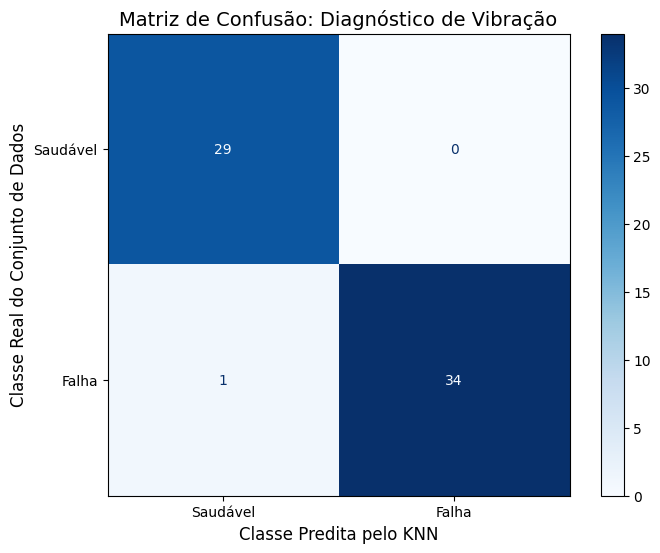


             DETALHAMENTO DA MATRIZ DE CONFUSÃO
Verdadeiros Negativos (Saudável -> Saudável) : 29
Falsos Positivos      (Saudável -> Falha)    : 0 (Alarmes Falsos)
Verdadeiros Positivos (Falha -> Falha)       : 34
Falsos Negativos      (Falha -> Saudável)    : 1 (Omissões de Falha)
Amostras Totais Avaliadas: 64


In [ ]:
# 1. Obter a Matriz de Confusão e extrair valores absolutos
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# 2. Cálculos Métricos (Termos de Diagnóstico)
sensibilidade = tp / (tp + fn)
especificidade = tn / (tn + fp)
acuracia_global = (tp + tn) / (tp + tn + fp + fn)

# 3. Exibição da Matriz Gráfica
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                               display_labels=['Saudável', 'Falha'],
                                               cmap='Blues',
                                               ax=ax)

ax.set_title("Matriz de Confusão: Diagnóstico de Vibração", fontsize=14)
ax.set_xlabel("Classe Predita pelo KNN", fontsize=12)
ax.set_ylabel("Classe Real do Conjunto de Dados", fontsize=12)
plt.show()

# 4. Impressão da Matriz Numérica e Relatório de Indicadores
print("\n" + "="*70)
print("             DETALHAMENTO DA MATRIZ DE CONFUSÃO")
print("="*70)
print(f"Verdadeiros Negativos (Saudável -> Saudável) : {tn}")
print(f"Falsos Positivos      (Saudável -> Falha)    : {fp} (Alarmes Falsos)")
print(f"Verdadeiros Positivos (Falha -> Falha)       : {tp}")
print(f"Falsos Negativos      (Falha -> Saudável)    : {fn} (Omissões de Falha)")
print(f"Amostras Totais Avaliadas: {len(y_test)}")
print("="*70)



In [ ]:
# Extrai do Grid Search o pipeline completo contendo a melhor combinação de hiperparâmetros encontrada
best_model = grid_search.best_estimator_

# Submete os dados brutos de teste (X_test) ao pipeline vencedor para realizar as predições das faixas do IPCA
y_pred_best = best_model.predict(X_test)

# Calculando métricas para a classe 'Saudável' (0)
precision_healthy = precision_score(y_test, y_pred_best, pos_label=0)
recall_healthy = recall_score(y_test, y_pred_best, pos_label=0)
f1_healthy = f1_score(y_test, y_pred_best, pos_label=0)

# Calculando métricas para a classe 'Falha' (1)
precision_faulty = precision_score(y_test, y_pred_best, pos_label=1)
recall_faulty = recall_score(y_test, y_pred_best, pos_label=1)
f1_faulty = f1_score(y_test, y_pred_best, pos_label=1)

acuracia_global = accuracy_score(y_test, y_pred_best)

# --- Cálculo do AUC-ROC e Intervalo de Confiança ---
# Obter as probabilidades da classe positiva (classe 1 - 'Falha')
y_prob = best_model.predict_proba(X_test)[:, 1]

# Calcular o AUC-ROC
auc_roc = roc_auc_score(y_test, y_prob)

# Bootstrapping para o Intervalo de Confiança do AUC-ROC
n_bootstraps = 1000 # Número de reamostragens
auc_scores_bootstrap = []
rng = np.random.RandomState(RANDOM_STATE) # Para reprodutibilidade

for i in range(n_bootstraps):
    # Reamostrar com substituição
    indices = rng.choice(len(y_test), len(y_test), replace=True)
    y_test_resampled = y_test.iloc[indices] # Garante que y_test é um Series/DataFrame
    y_prob_resampled = y_prob[indices]

    # Pular reamostras que não contêm ambas as classes
    if len(np.unique(y_test_resampled)) < 2:
        continue

    auc_scores_bootstrap.append(roc_auc_score(y_test_resampled, y_prob_resampled))

# Calcular o 95% Intervalo de Confiança
lower_bound_auc = np.percentile(auc_scores_bootstrap, 2.5)
upper_bound_auc = np.percentile(auc_scores_bootstrap, 97.5)

# Criando um DataFrame para exibir os resultados com descrições
report_data = [
    {
        "Métrica": "Precision (Saudável)",
        "Valor": f"{precision_healthy:.4f}",
        "Descrição": "Precisão para a classe 'Saudável'."
    },
    {
        "Métrica": "Recall (Saudável)",
        "Valor": f"{recall_healthy:.4f}",
        "Descrição": "Recall para a classe 'Saudável'."
    },
    {
        "Métrica": "F1-Score (Saudável)",
        "Valor": f"{f1_healthy:.4f}",
        "Descrição": "F1-Score para a classe 'Saudável'."
    },
    {
        "Métrica": "Precision (Falha)",
        "Valor": f"{precision_faulty:.4f}",
        "Descrição": "Precisão para a classe 'Falha'."
    },
    {
        "Métrica": "Recall (Falha)",
        "Valor": f"{recall_faulty:.4f}",
        "Descrição": "Recall para a classe 'Falha'."
    },
    {
        "Métrica": "F1-Score (Falha)",
        "Valor": f"{f1_faulty:.4f}",
        "Descrição": "F1-Score para a classe 'Falha'."
    },
    {
        "Métrica": "Acurácia Global",
        "Valor": f"{acuracia_global:.4f}",
        "Descrição": "Acurácia geral do modelo."
    },
    {
        "Métrica": "AUC-ROC",
        "Valor": f"{auc_roc:.4f}",
        "Descrição": "Área sob a curva ROC."
    },
    {
        "Métrica": "IC 95% AUC-ROC",
        "Valor": f"[{lower_bound_auc:.4f}, {upper_bound_auc:.4f}]",
        "Descrição": "Intervalo de confiança de 95% para o AUC-ROC"
    }
]

df_report = pd.DataFrame(report_data)

print("\n" + "="*70)
print("               RELATÓRIO DE DESEMPENHO")
print("="*70)
print(df_report.to_string(index=False))
print("="*70)


               RELATÓRIO DE DESEMPENHO
             Métrica            Valor                                    Descrição
Precision (Saudável)           0.9667           Precisão para a classe 'Saudável'.
   Recall (Saudável)           1.0000             Recall para a classe 'Saudável'.
 F1-Score (Saudável)           0.9831           F1-Score para a classe 'Saudável'.
   Precision (Falha)           1.0000              Precisão para a classe 'Falha'.
      Recall (Falha)           0.9714                Recall para a classe 'Falha'.
    F1-Score (Falha)           0.9855              F1-Score para a classe 'Falha'.
     Acurácia Global           0.9844                    Acurácia geral do modelo.
             AUC-ROC           1.0000                        Área sob a curva ROC.
      IC 95% AUC-ROC [1.0000, 1.0000] Intervalo de confiança de 95% para o AUC-ROC


# Pipeline - Resultados do GridSearchCV

In [ ]:
# Converte o dicionário completo de resultados históricos do Grid Search em um DataFrame do Pandas
results = pd.DataFrame(grid_search.cv_results_)

# Cria uma lista contendo os nomes das colunas de interesse (hiperparâmetros testados e métricas de score)
cols = [
    'param_model__n_neighbors', # Número de vizinhos (k) testado na rodada
    'param_model__weights',     # Função de peso testada ('uniform' ou 'distance')
    'param_model__metric',      # Métrica de distância testada ('euclidean' ou 'manhattan')
    'mean_test_score',          # Média aritmética da acurácia obtida pelo modelo ao longo dos 5 folds da rodada
    'std_test_score',           # Desvio padrão (variabilidade) da acurácia entre as divisões da validação cruzada
    'rank_test_score'           # Posição hierárquica (ranking) da combinação de parâmetros frente às demais testadas
]

# Filtra as colunas selecionadas, ordena de forma crescente pelo ranking e exibe as 10 melhores configurações
results[cols].sort_values('rank_test_score').head(10)

,param_model__n_neighbors,param_model__weights,param_model__metric,mean_test_score,std_test_score,rank_test_score
3,5,distance,euclidean,0.973333,0.024944,1
0,3,uniform,euclidean,0.973103,0.025010,2
1,3,distance,euclidean,0.973103,0.025010,2
2,5,uniform,euclidean,0.966667,0.029814,4
11,3,distance,manhattan,0.966437,0.036518,5
5,7,distance,euclidean,0.959770,0.032616,6
7,9,distance,euclidean,0.959770,0.032616,6
10,3,uniform,manhattan,0.952874,0.034275,8
13,5,distance,manhattan,0.946207,0.034186,9
4,7,uniform,euclidean,0.946207,0.034186,9


# Cálculo do Dataset
## Normalizado (resultante euclidiana),
## Limpo (outliers removidos) e
## Escalonado (Z-Scaler)

### Entrada: Dataset Normalizado e Limpo

In [ ]:
# Separar as colunas de features do target no dataset filtrado
X_filtrado = df_treino_filtrado.drop('target', axis=1)
y_filtrado = df_treino_filtrado['target']

# Criar e aplicar um novo scaler no dataset filtrado
scaler_filtrado = StandardScaler()
X_filtrado_scaled = scaler_filtrado.fit_transform(X_filtrado)

# Converter de volta para DataFrame para manter os nomes das colunas
df_treino_filtrado_scaled = pd.DataFrame(X_filtrado_scaled, columns=X_filtrado.columns)
df_treino_filtrado_scaled['target'] = y_filtrado.values

print("\n" + "="*70)
print("        “DATASET” FINAL (NORMALIZADO, LIMPO E ESCALONADO)")
print("="*70)
print(df_treino_filtrado_scaled.describe().round(4))


        “DATASET” FINAL (NORMALIZADO, LIMPO E ESCALONADO)
            rms   curtose  fator_crista    amp_1x    amp_2x    amp_3x  \
count  213.0000  213.0000      213.0000  213.0000  213.0000  213.0000   
mean    -0.0000    0.0000       -0.0000   -0.0000   -0.0000    0.0000   
std      1.0024    1.0024        1.0024    1.0024    1.0024    1.0024   
min     -2.1366   -0.8470       -1.2590   -1.1559   -1.3944   -1.3099   
25%     -0.2859   -0.5786       -1.0956   -0.9230   -0.8826   -0.8921   
50%      0.0403   -0.3634        0.1211   -0.3092   -0.3083   -0.3010   
75%      0.2102    0.1169        0.5653    0.7067    0.8077    0.8466   
max      8.8605    5.5352        4.8729    2.4206    2.2719    2.0137   

         target  
count  213.0000  
mean     0.5493  
std      0.4987  
min      0.0000  
25%      0.0000  
50%      1.0000  
75%      1.0000  
max      1.0000  


# 3.12 Mapeamento do Espaço de Estados e Fronteiras de Decisão

## Entrada: Dataset Normalizado, Limpo e Escalonado

A visualização tridimensional do *dataset* (Figura 13) revela a configuração geométrica que sustenta a alta performance do classificador KNN. Ao projetar as amostras em um espaço de estados composto pelas amplitudes de 3X, 2X e 1X, observa-se uma segregação espacial nítida entre as classes. As amostras correspondentes ao estado “Saudável” (em azul) agrupam-se em uma região de baixa energia e baixa frequência, com baixa amplitude de 1X, amplitude distribuída de 2X e extremamente baixa de 3X, formando uma nuvem de pontos em uma região bem delimitada.

Diferentemente, as amostras do estado “Falha” (em vermelho) distribuem-se em 3 regiões distintas do espaço de atributos de frequência: uma dispersa entre pontos do estado “Saudável”; a segunda praticamente no plano formado entre 2X e 3X, nas amplitudes entre 0,5 e 1,0, para uma amplitude de 1X na ordem de -1,0; e a última também, aproximadamente, no plano 2X e 3X, nas amplitudes aproximadamente entre 2,0 e 1,5, manifestando uma dispersão maior se comparada ao estado “Saudável”, o que reflete o comportamento instável da anomalia mecânica.

Esta organização espacial confirma que os atributos espectrais selecionados são preditores altamente eficazes, transformando sinais temporais em coordenadas cartesianas onde a integridade da máquina pode ser analisada. Portanto, a distribuição 3D confirma a eficácia da engenharia de atributos, garantindo que o algoritmo consiga diferenciar entre o estado “Saudável” e a “Falha” com precisão.

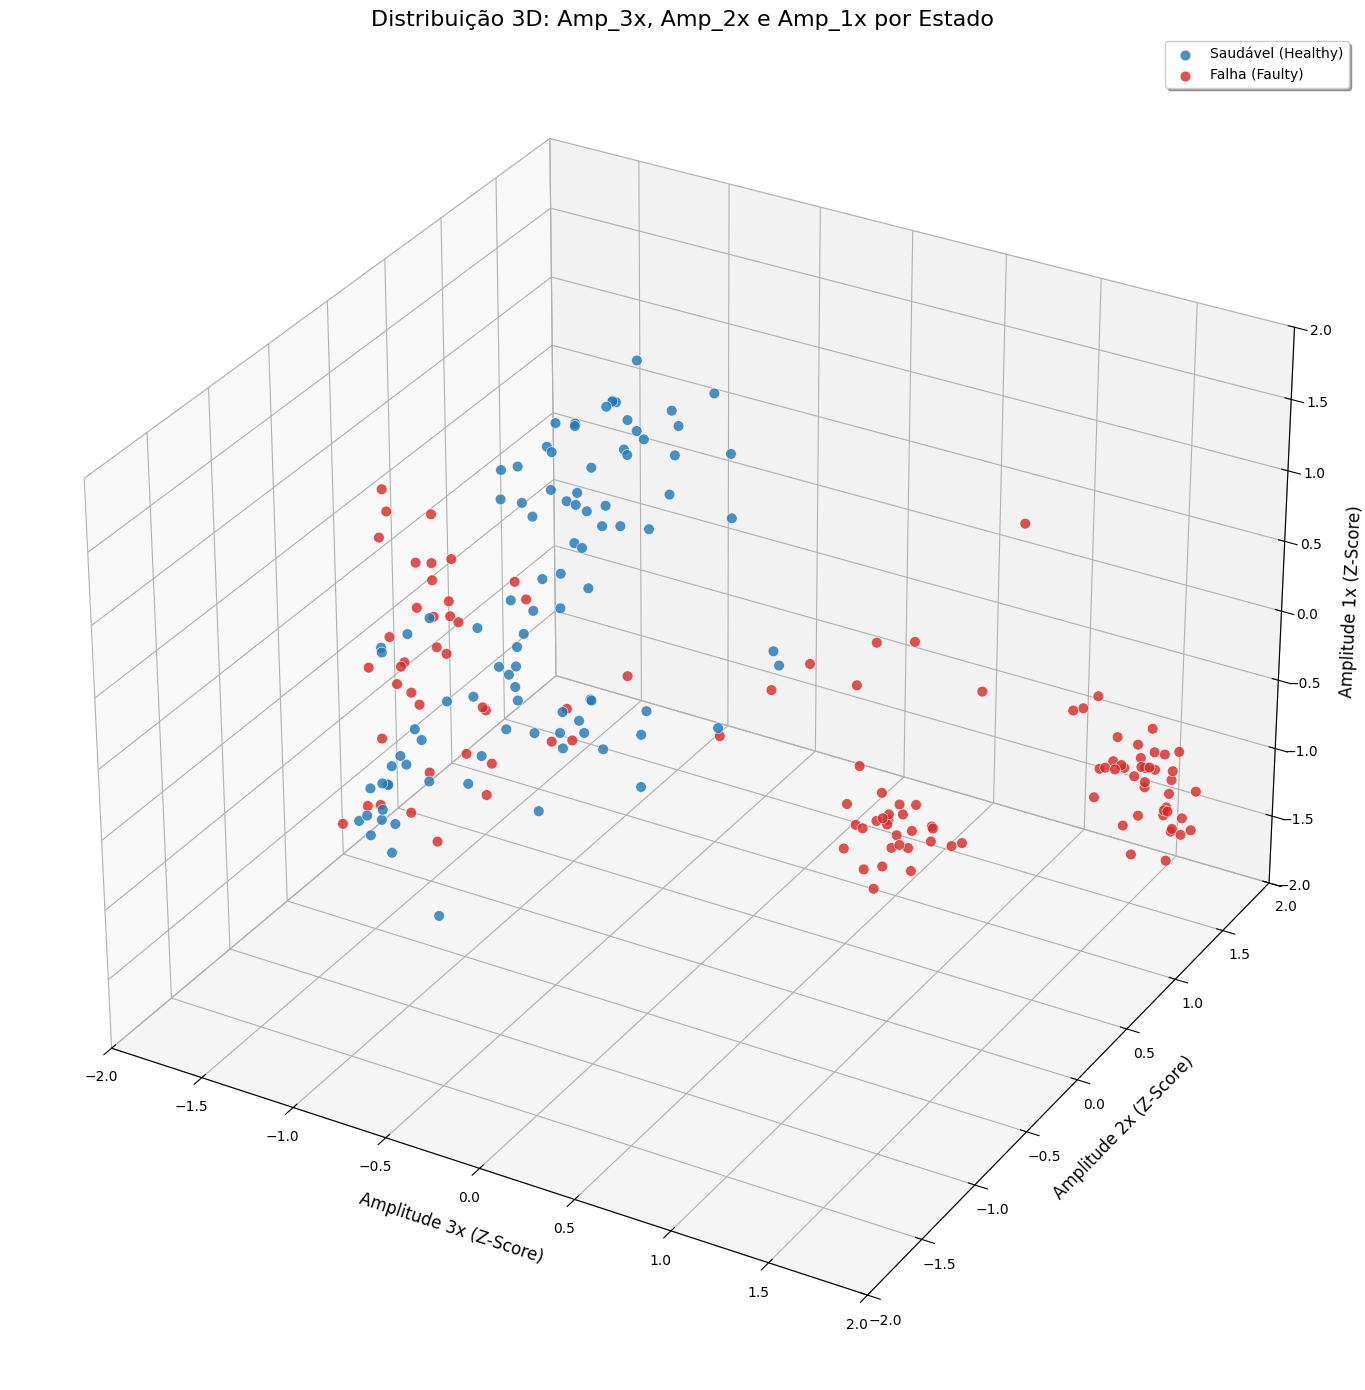

In [ ]:
def plotar_grafico_3d_features(df):
    # 1. Preparação
    X = df[['amp_3x', 'amp_2x', 'amp_1x']].values # Use 3 features: Amp_3x, Amp_2x, Amp_1x
    y = df['target'].values

    # 2. Cores Acadêmicas
    cmap_bold = ['#1f77b4', '#d62728'] # Blue for Healthy, Red for Faulty

    fig = plt.figure(figsize=(21, 14))
    ax = fig.add_subplot(111, projection='3d')

    # Pontos reais
    for i, condicao in enumerate(['Saudável (Healthy)', 'Falha (Faulty)']):
        indices = y == i
        ax.scatter(X[indices, 0], X[indices, 1], X[indices, 2], c=cmap_bold[i],
                   edgecolor='white', linewidth=0.5, s=60, label=condicao, alpha=0.8)

    ax.set_xlabel('Amplitude 3x (Z-Score)', fontsize=12, labelpad=10)
    ax.set_ylabel('Amplitude 2x (Z-Score)', fontsize=12, labelpad=10)
    ax.set_zlabel('Amplitude 1x (Z-Score)', fontsize=12, labelpad=10) # Updated z-label

    ax.set_title('Distribuição 3D: Amp_3x, Amp_2x e Amp_1x por Estado', fontsize=16)
    ax.legend(loc='upper right', frameon=True, shadow=True)
    ax.grid(True, linestyle=':', alpha=0.6)

    # Definir os limites dos eixos conforme solicitado
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_zlim(-2, 2)

    plt.tight_layout()
    plt.show()

# Call the function with the scaled and filtered DataFrame
plotar_grafico_3d_features(df_treino_filtrado_scaled)

# Visualização 3D dos Atributos - Dominio do Tempo

## Entrada: Dataset Normalizado, Limpo e Escalonado

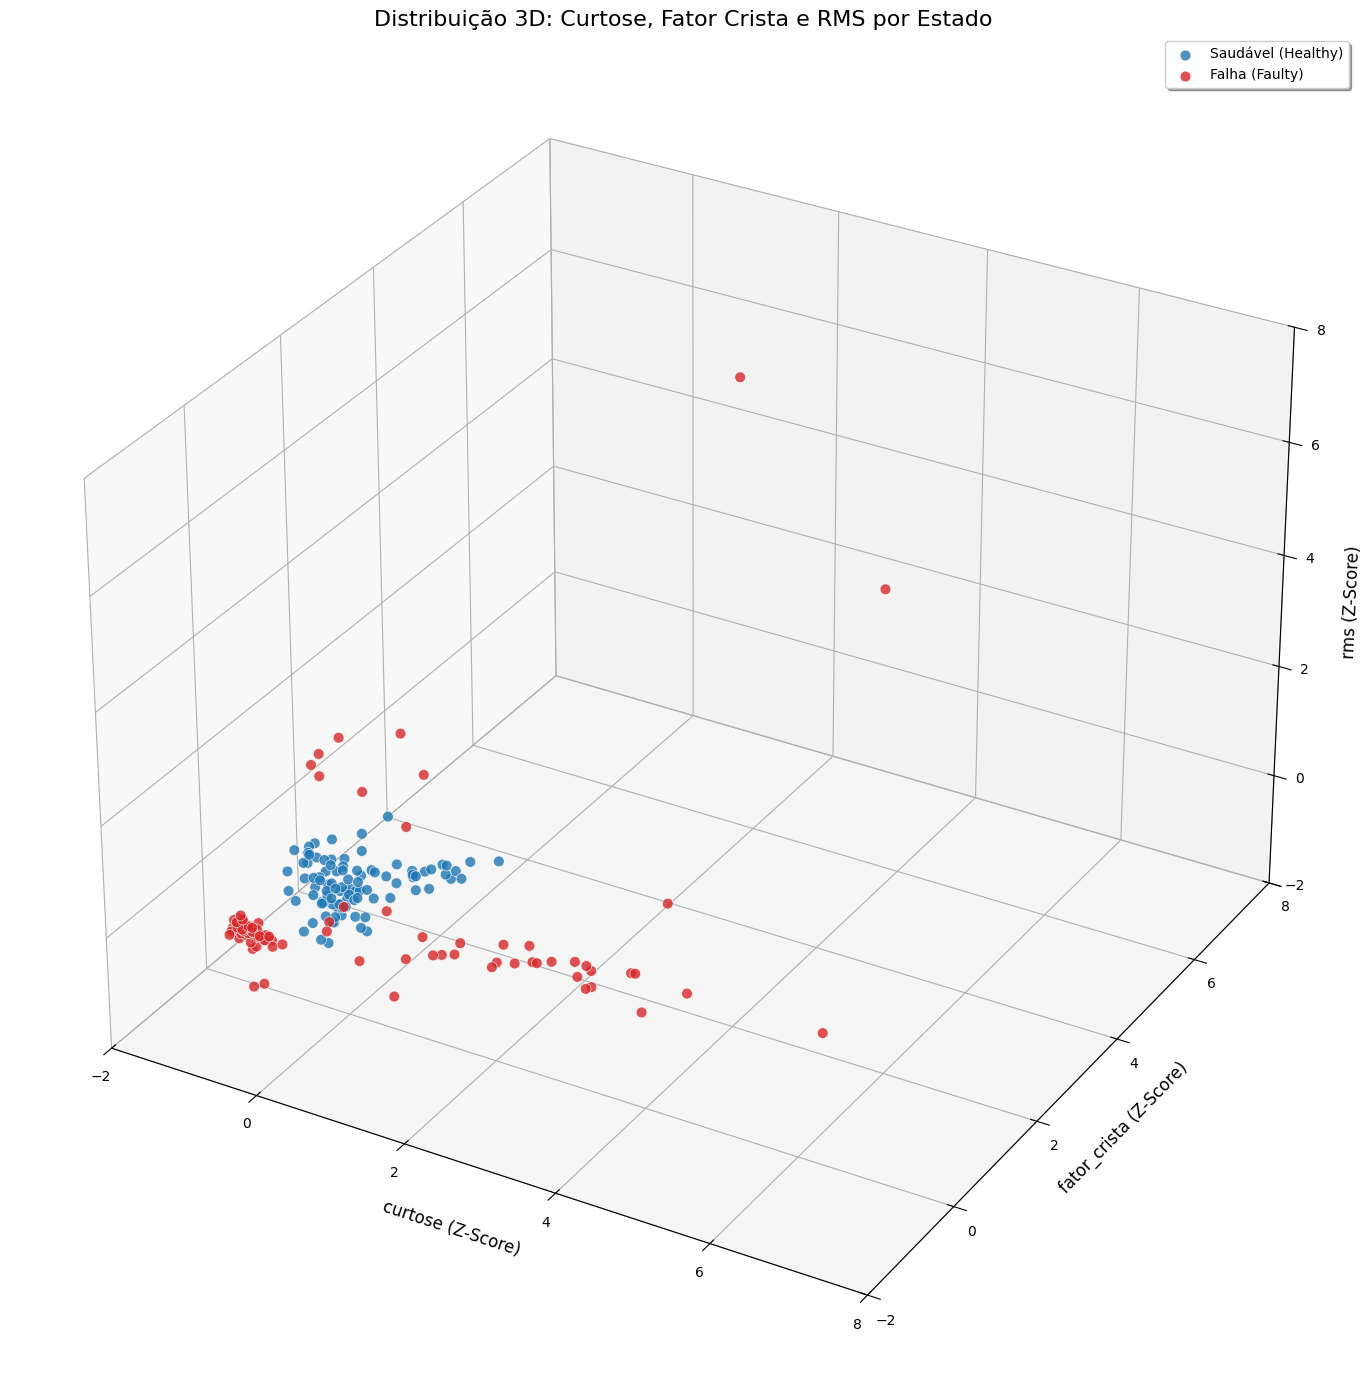

In [ ]:
def plotar_grafico_3d_features(df):
    # 1. Preparação
    X = df[['curtose', 'fator_crista', 'rms']].values # Use 3 features: curtose, fator_crista, rms
    y = df['target'].values

    # 2. Cores Acadêmicas
    cmap_bold = ['#1f77b4', '#d62728'] # Blue for Healthy, Red for Faulty

    fig = plt.figure(figsize=(21, 14))
    ax = fig.add_subplot(111, projection='3d')

    # Pontos reais
    for i, condicao in enumerate(['Saudável (Healthy)', 'Falha (Faulty)']):
        indices = y == i
        ax.scatter(X[indices, 0], X[indices, 1], X[indices, 2], c=cmap_bold[i],
                   edgecolor='white', linewidth=0.5, s=60, label=condicao, alpha=0.8)

    ax.set_xlabel('curtose (Z-Score)', fontsize=12, labelpad=10)
    ax.set_ylabel('fator_crista (Z-Score)', fontsize=12, labelpad=10)
    ax.set_zlabel('rms (Z-Score)', fontsize=12, labelpad=10)

    ax.set_title('Distribuição 3D: Curtose, Fator Crista e RMS por Estado', fontsize=16)
    ax.legend(loc='upper right', frameon=True, shadow=True)
    ax.grid(True, linestyle=':', alpha=0.6)

    # Definir os limites dos eixos conforme solicitado
    ax.set_xlim(-2, 8)
    ax.set_ylim(-2, 8)
    ax.set_zlim(-2, 8)

    plt.tight_layout()
    plt.show()

# Call the function with the scaled and filtered DataFrame
plotar_grafico_3d_features(df_treino_filtrado_scaled)

# 4.	CONSIDERAÇÕES FINAIS
As considerações finais deste trabalho ratificam a robustez da metodologia proposta, evidenciando que a integração entre o processamento digital de sinais e o aprendizado de máquina oferece uma solução de alta confiabilidade para o diagnóstico de ativos rotativos. A estratégia de fusão de dados triaxiais por meio da Resultante Euclidiana demonstrou ser um passo fundamental, ao consolidar as variações espaciais da vibração em um vetor de magnitude único, preservando a sensibilidade diagnóstica necessária para a detecção de anomalias.


A análise estatística aplicada no pré-processamento mostrou-se determinante para a estabilidade do modelo. A limpeza via IQR foi eficaz na remoção “outliers” que poderiam corromper a interpretação do estado “Saudável”, enquanto o escalonamento via Z-Score equalizou as escalas de grandezas físicas distintas, como energia temporal e amplitudes espectrais. Esse tratamento preparou os dados adequadamente para a definição de fronteiras de decisão geometricamente nítidas no espaço de atributos. Essa consistência foi maximizada pela otimização via “Grid Search”, que determinou matematicamente a arquitetura ideal do classificador KNN com k=5 vizinhos e ponderação baseada na distância.


A transição e classificação do estado “Saudável” para “Falha” manifestou-se por meio de uma redistribuição energética severa, marcada pelas harmônicas de 2ª e 3ª ordem com altos fatores positivos de correlação e do lado oposto a 1ª harmônica com alto fator de correlação, mas negativo, todos validados pelo cálculo da correlação ponto-bisserial. A resposta do classificador confirmou a eficiência desse mapeamento, atingindo uma acurácia global de 98,44% no teste estático e uma acurácia média de 96,72% via validação cruzada K-Fold, mitigando o risco de sobreajuste. O equilíbrio do modelo foi ratificado por índices de F1-Score superiores a 0,98 em ambas as classes e um intervalo de confiança rígido para o AUC-ROC.


Esse patamar de desempenho posiciona o presente estudo em linha com fronteiras complexas da literatura, demonstrando que o modelo proposto, de baixa complexidade computacional, atinge uma performance estatisticamente equivalente à acurácia de 98,61% obtida por Xia et al. (2018) com Redes Neurais Convolucionais (CNN) aplicadas a múltiplos sensores em cenários similares. Evidencia-se, assim, que a correta estruturação e refinamento estatístico dos atributos superam a necessidade de arquiteturas de aprendizado profundo (“deep learning”) para a extração de assinaturas de falha. De grande relevância prática industrial, a especificidade de 100% assegura a eliminação de alarmes falsos em ambiente fabril.


Como perspectiva para trabalhos futuros, vislumbra-se a integração desta metodologia com sistema SCADA (Supervisão, Controle e Aquisição de Dados), permitindo que a detecção de falhas ocorra em tempo real no nível de controle da planta. Dada a realidade industrial onde os ativos raramente possuem dados previamente rotulados, a evolução deste trabalho aponta para o uso de Machine Learning não supervisionado. Tal abordagem permitirá que o sistema aprenda o padrão de comportamento nominal do ativo diretamente com o histórico de variáveis de processo do SCADA, identificando desvios como potenciais falhas sem a necessidade de etiquetas prévias de “Saudável” ou “Falha”. Essa transição converterá o diagnóstico estático em um sistema de prognóstico em tempo real, capaz de rastrear a evolução da degradação do ativo em seu regime permanente de operação.
